# California Rice Monitoring — Colab Analysis and Machine Learning

This notebook uses analysis-ready data created on EC2 from raw MODIS, PRISM, and CDL data. Rather than reprocessing the large raw archive in Colab, it starts from the compact outputs produced by Steps 20–26.

Main objectives:

- Verify the EC2 → Colab data handoff
- Review USDA NASS yield and production together with CDL-derived rice area
- Examine relationships between seasonal/monthly satellite and climate indicators and rice yield
- Evaluate machine-learning models carefully for 2007–2025 using **Leave-One-Year-Out cross-validation (LOOCV)**
- Save figures, tables, and compact summaries of the analysis results

### Scientific rules

- Primary targets are `nass_yield_lb_acre` and `nass_production_cwt`
- NASS planted acreage, harvested acreage, and other NASS outcome variables are not used as predictors
- UMT/NTSG GPP and MOD17 GPP are kept as separate series; missing values are not filled across products
- The main 19-year ML analysis uses only predictors with complete coverage over the full period
- Random train/test splitting is not used; each predicted year is completely excluded from model training
- Because there are only 19 annual samples, ML results are interpreted as exploratory


## 0. Colab Setup

Copy the entire EC2 `processed/` directory to Google Drive before running this notebook.

Set `PROJECT_ROOT` to your own project folder in Google Drive. The public version uses `YOUR_PROJECT_FOLDER` as a generic placeholder and contains no user-specific Drive path.


In [1]:
%pip -q install pyarrow scikit-learn scipy


In [2]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/YOUR_PROJECT_FOLDER")
if "YOUR_PROJECT_FOLDER" in str(PROJECT_ROOT):
    raise ValueError("Set PROJECT_ROOT to your own Google Drive project folder.")

PROCESSED = PROJECT_ROOT / "processed"

assert PROCESSED.exists(), (
    f"{PROCESSED} does not exist. Copy EC2 processed/ there or edit PROJECT_ROOT."
)

OUTPUT_ROOT = PROJECT_ROOT / "analysis_outputs"
FIG_DIR = OUTPUT_ROOT / "figures"
TABLE_DIR = OUTPUT_ROOT / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROCESSED   :", PROCESSED)
print("OUTPUT_ROOT :", OUTPUT_ROOT)


Mounted at /content/drive
PROJECT_ROOT: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4
PROCESSED   : /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/processed
OUTPUT_ROOT : /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs


<details>
<summary><b>How this setup works: Colab and Google Drive</b></summary>

- Google Drive is mounted at `/content/drive`, and `PROJECT_ROOT` becomes the base directory for the analysis.
- The notebook stops immediately if `PROCESSED` does not exist, preventing later cells from reading from an incorrect location.
- `analysis_outputs/figures` and `analysis_outputs/tables` are created automatically and used for subsequent outputs.

</details>


## 1. Libraries and Helper Functions

`numpy`, `pandas`, `scipy`, and `scikit-learn` are used for data analysis, statistics, and machine learning.

Figures are saved in both PNG and SVG formats. PNG is convenient for raster output, while SVG provides scalable vector output.


In [3]:
import json, math, warnings, shutil
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import pearsonr, spearmanr, zscore

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, LeaveOneOut
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)
RANDOM_STATE = 42

TARGET_COLS = [
    "nass_planted_acres",
    "nass_harvested_acres",
    "nass_yield_lb_acre",
    "nass_production_cwt",
]

AREA_COLS = [
    "cdl_rice_pixels",
    "cdl_rice_area_hectares",
    "cdl_rice_area_acres",
]

def savefig(name, dpi=220):
    png = FIG_DIR / f"{name}.png"
    svg = FIG_DIR / f"{name}.svg"
    plt.tight_layout()
    plt.savefig(png, dpi=dpi, bbox_inches="tight")
    plt.savefig(svg, bbox_inches="tight")
    print("saved:", png)
    print("saved:", svg)


<details>
<summary><b>How the main variable groups are used</b></summary>

- `TARGET_COLS` contains the NASS outcome variables. Excluding them from predictors helps prevent target leakage.
- `AREA_COLS` contains pixel, hectare, and acre representations of the same CDL rice footprint. For ML, `cdl_rice_area_acres` is used as the representative area variable when needed.
- `savefig()` saves each figure in both PNG and SVG formats.

</details>


## 2. Load Analysis-Ready Data Produced on Local Machine

Load the final outputs from Step 25: the annual ML table, monthly timing table, NASS statistics, QC tables, and feature dictionaries.


In [4]:
P25 = PROCESSED / "25_nass_outcomes"
P24 = PROCESSED / "24_analysis_ready"

paths = {
    "yearly": P25 / "model_yearly.parquet",
    "monthly": P25 / "monthly_features_with_nass.parquet",
    "seasonal": P25 / "seasonal_features_with_nass.parquet",
    "nass": P25 / "nass_yearly.parquet",
    "area_qc": P25 / "_manifests" / "nass_cdl_area_comparison.csv",
    "nass_qc": P25 / "_manifests" / "nass_quality.csv",
    "target_dict": P25 / "_manifests" / "feature_dictionary_targets.csv",
    "feature_dict": P24 / "_manifests" / "feature_dictionary.csv",
    "monthly_qc": P24 / "_manifests" / "monthly_quality.csv",
}
missing = [p for p in paths.values() if not p.exists()]
assert not missing, "Missing required files:\n" + "\n".join(map(str, missing))

yearly = pd.read_parquet(paths["yearly"]).sort_values("year").reset_index(drop=True)
monthly = pd.read_parquet(paths["monthly"]).sort_values(["year","month"]).reset_index(drop=True)
seasonal_joined = pd.read_parquet(paths["seasonal"]).sort_values("year").reset_index(drop=True)
nass = pd.read_parquet(paths["nass"]).sort_values("year").reset_index(drop=True)

area_qc = pd.read_csv(paths["area_qc"])
nass_qc = pd.read_csv(paths["nass_qc"])
target_dict = pd.read_csv(paths["target_dict"])
feature_dict = pd.read_csv(paths["feature_dict"])
monthly_qc = pd.read_csv(paths["monthly_qc"])

print("yearly :", yearly.shape)
print("monthly:", monthly.shape)
print("years  :", yearly.year.min(), "-", yearly.year.max())
display(yearly.head())


yearly : (19, 36)
monthly: (152, 37)
years  : 2007 - 2025


,year,blue,et,evi,fpar,gpp_mod17,gpp_ntsg,green,lai,lst_day_c,...,tmin_c,vpdmax_hpa,vpdmin_hpa,cdl_rice_pixels,cdl_rice_area_hectares,cdl_rice_area_acres,nass_harvested_acres,nass_planted_acres,nass_production_cwt,nass_yield_lb_acre
0,2007,0.040296,419.425617,0.320934,0.443427,NaN,1.674376,0.078138,1.509302,22.027225,...,11.201934,29.011159,2.453472,818838,256787.5968,634535.970633,533000.0,534000.0,43684000.0,8200.0
1,2008,0.041553,390.574032,0.331132,0.438447,NaN,1.597064,0.079989,1.511221,21.750778,...,11.539025,30.788840,3.119250,2464453,221800.7700,548081.638806,517000.0,519000.0,43030000.0,8320.0
2,2009,0.040605,424.340611,0.342978,0.455629,NaN,1.692144,0.078795,1.605483,21.384846,...,11.474577,29.220451,2.324484,2649409,238446.8100,589214.899447,556000.0,561000.0,47804000.0,8600.0
3,2010,0.039417,510.741320,0.340516,0.462280,NaN,1.738858,0.076906,1.598583,19.048351,...,10.890547,25.737249,2.085233,2706692,243602.2800,601954.343257,553000.0,558000.0,44326000.0,8020.0
4,2011,0.038422,513.710866,0.338590,0.457868,NaN,1.892060,0.075288,1.642418,19.807814,...,11.248063,25.294031,1.924039,2701027,243092.4300,600694.476469,580000.0,585000.0,48402000.0,8350.0


<details>
<summary><b>Result interpretation: analysis-ready table structure</b></summary>

The executed workflow produced **19 rows × 36 columns for `yearly`, 152 rows × 37 columns for `monthly`, covering 2007–2025**.

- `yearly` contains one row per year.
- `monthly` contains 19 years × 8 months (April–November) = 152 rows.
- Satellite and climate features, CDL-derived rice area, and NASS outcome variables are joined in the same tables.
- Early-year `gpp_mod17 = NaN` values are expected rather than errors. MOD17 and NTSG GPP are treated as separate products and are not forced into a single continuous series.
- For comparisons across years, `cdl_rice_area_acres` is safer to interpret than raw CDL pixel counts.

</details>


## 3. Strict Handoff QC

Expected structure:

- Annual data: 19 rows for 2007–2025
- Monthly data: 19 years × 8 months (April–November) = 152 rows
- No missing values in the four annual NASS outcome variables


In [5]:
EXPECTED_YEARS = list(range(2007, 2026))
EXPECTED_MONTHS = list(range(4, 12))

assert yearly["year"].astype(int).tolist() == EXPECTED_YEARS
assert len(yearly) == 19
assert len(monthly) == 19 * 8
assert sorted(monthly["month"].astype(int).unique().tolist()) == EXPECTED_MONTHS

for c in TARGET_COLS:
    assert c in yearly.columns
    assert yearly[c].notna().all(), f"Missing NASS values in {c}"

qc_summary = pd.DataFrame({
    "item": ["annual_rows","monthly_rows","annual_years","months","target_missing_total"],
    "value": [
        len(yearly),
        len(monthly),
        f"{yearly.year.min()}-{yearly.year.max()}",
        ",".join(map(str, sorted(monthly.month.unique()))),
        int(yearly[TARGET_COLS].isna().sum().sum()),
    ],
})
display(qc_summary)
qc_summary.to_csv(TABLE_DIR / "00_handoff_qc_summary.csv", index=False)


,item,value
0,annual_rows,19
1,monthly_rows,152
2,annual_years,2007-2025
3,months,"4,5,6,7,8,9,10,11"
4,target_missing_total,0


<details>
<summary><b>Result interpretation: handoff QC</b></summary>

All handoff checks matched the expected structure.

- Annual rows: **19**
- Monthly rows: **152**
- Years: **2007–2025**
- Months: **April–November**
- Missing NASS target values: **0**

This confirms that the final EC2 products were transferred to Colab without missing years or target values and are ready for the main analysis.

</details>


## 4. Feature Availability by Time Period

GPP products have different periods of availability. Missing years are not artificially filled, and the main 19-year ML analysis uses only predictors with complete coverage over the full period.


In [6]:
numeric_yearly = yearly.select_dtypes(include=np.number)
predictor_like = [c for c in numeric_yearly.columns if c not in ["year"] + TARGET_COLS]

availability = pd.DataFrame({
    "feature": predictor_like,
    "nonmissing_years": [int(yearly[c].notna().sum()) for c in predictor_like],
    "missing_years": [int(yearly[c].isna().sum()) for c in predictor_like],
})
availability["coverage_fraction"] = availability["nonmissing_years"] / len(yearly)
availability = availability.sort_values(["nonmissing_years","feature"]).reset_index(drop=True)

display(availability)
availability.to_csv(TABLE_DIR / "01_seasonal_feature_availability.csv", index=False)

print("Incomplete full-period features:")
display(availability[availability["missing_years"] > 0])


,feature,nonmissing_years,missing_years,coverage_fraction
0,gpp_mod17,5,14,0.263158
1,psn_net_mod17,5,14,0.263158
2,gpp_ntsg,12,7,0.631579
3,blue,19,0,1.000000
4,cdl_rice_area_acres,19,0,1.000000
5,cdl_rice_area_hectares,19,0,1.000000
6,cdl_rice_pixels,19,0,1.000000
7,et,19,0,1.000000
8,evi,19,0,1.000000
9,fpar,19,0,1.000000


Incomplete full-period features:


,feature,nonmissing_years,missing_years,coverage_fraction
0,gpp_mod17,5,14,0.263158
1,psn_net_mod17,5,14,0.263158
2,gpp_ntsg,12,7,0.631579


<details>
<summary><b>Result interpretation: feature availability</b></summary>

The main incomplete features are the GPP-related series.

- `gpp_mod17`: available for 5 years, missing for 14 years
- `psn_net_mod17`: available for 5 years, missing for 14 years
- `gpp_ntsg`: available for 12 years, missing for 7 years
- Other major satellite, PRISM, and CDL features: available for all 19 years

Therefore, the primary 19-year ML analysis uses only complete-coverage predictors rather than artificially filling GPP gaps. GPP can still be used in EDA or shorter-period supplementary analyses.

</details>


## 5. Annual Trends in NASS Outcome Variables

Before fitting models, inspect how California rice planted acreage, harvested acreage, yield, and total production vary over time.


saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/02a_nass_yield.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/02a_nass_yield.svg


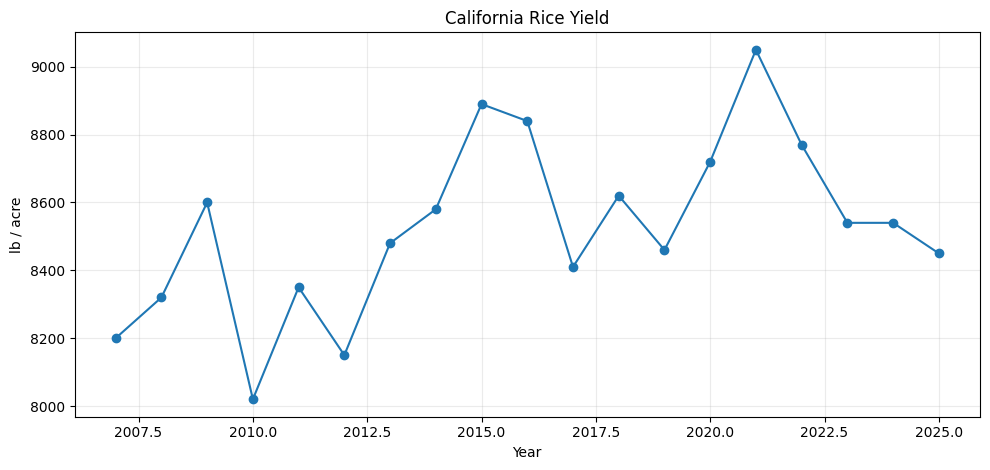

saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/02b_nass_production.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/02b_nass_production.svg


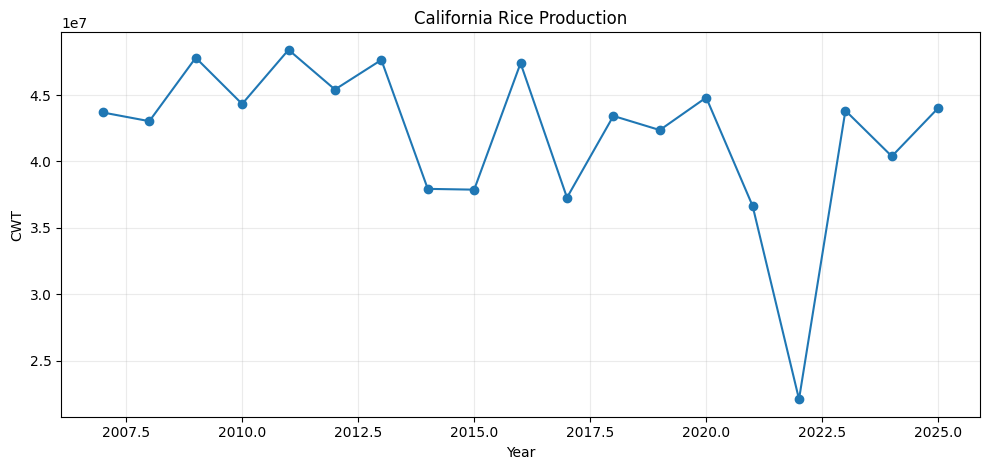

saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/02c_nass_planted.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/02c_nass_planted.svg


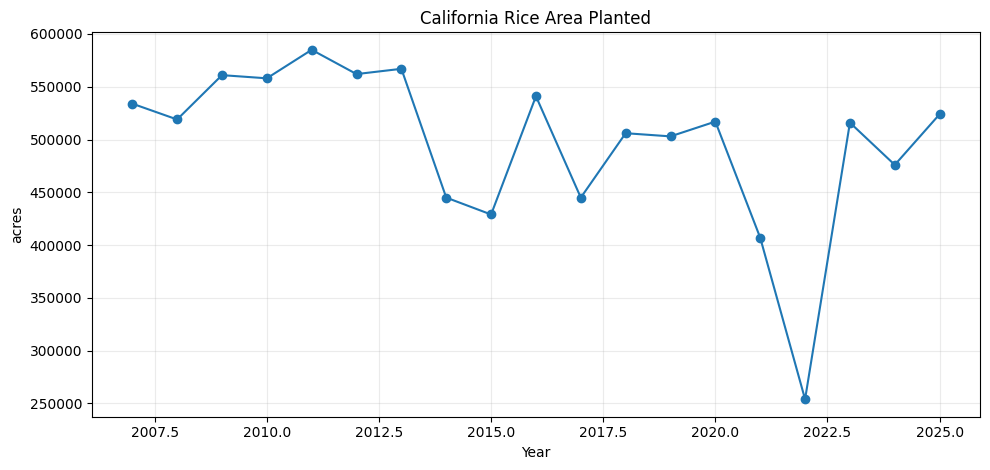

saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/02d_nass_harvested.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/02d_nass_harvested.svg


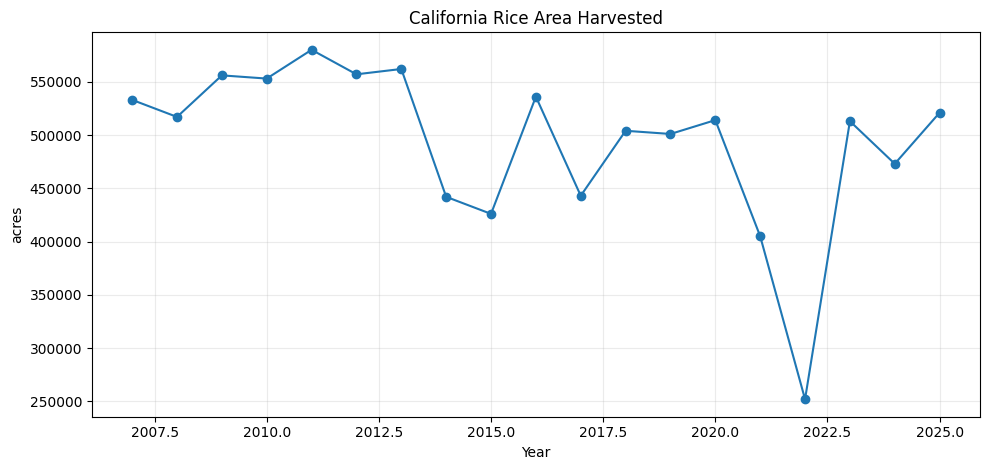

In [7]:
target_specs = [
    ("nass_yield_lb_acre", "California Rice Yield", "lb / acre", "02a_nass_yield"),
    ("nass_production_cwt", "California Rice Production", "CWT", "02b_nass_production"),
    ("nass_planted_acres", "California Rice Area Planted", "acres", "02c_nass_planted"),
    ("nass_harvested_acres", "California Rice Area Harvested", "acres", "02d_nass_harvested"),
]

for col, title, ylabel, fname in target_specs:
    plt.figure(figsize=(10,4.8))
    plt.plot(yearly["year"], yearly[col], marker="o")
    plt.title(title)
    plt.xlabel("Year")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    savefig(fname)
    plt.show()


<details>
<summary><b>Result interpretation: annual NASS trends</b></summary>

The four annual series show several clear patterns.

- Planted and harvested acreage follow very similar trajectories.
- Acreage varies substantially across years, with a particularly large contraction in **2022**.
- Yield is relatively stable compared with acreage, generally remaining around 8,000–9,100 lb/acre.
- Production closely follows the acreage pattern.

This suggests that statewide production variability is strongly influenced not only by yield, but also by **how much area is planted**. Yield remains a useful primary target for examining relationships with satellite and climate conditions.

</details>


## 6. Compare CDL Rice Area with USDA NASS Acreage

Compare rice area independently derived from CDL class 3 with USDA NASS planted and harvested acreage. This is an important QC step for checking whether the remote-sensing-derived area estimate tracks the year-to-year variation in agricultural statistics.


,year,cdl_rice_area_acres,nass_planted_acres,nass_harvested_acres,nass_yield_lb_acre,nass_production_cwt,nass_harvested_to_cdl_area_ratio,implied_production_cwt_from_harvest_yield,reported_to_implied_production_ratio
0,2007,634535.970633,534000.0,533000.0,8200.0,43684000.0,0.839984,43706000.0,0.999497
1,2008,548081.638806,519000.0,517000.0,8320.0,43030000.0,0.943290,43014400.0,1.000363
2,2009,589214.899447,561000.0,556000.0,8600.0,47804000.0,0.943629,47816000.0,0.999749
3,2010,601954.343257,558000.0,553000.0,8020.0,44326000.0,0.918674,44350600.0,0.999445
4,2011,600694.476469,585000.0,580000.0,8350.0,48402000.0,0.965549,48430000.0,0.999422
5,2012,583428.630413,562000.0,557000.0,8150.0,45413000.0,0.954701,45395500.0,1.000386
6,2013,577648.366041,567000.0,562000.0,8480.0,47641000.0,0.972910,47657600.0,0.999652
7,2014,472153.370558,445000.0,442000.0,8580.0,37936000.0,0.936136,37923600.0,1.000327
8,2015,442858.854611,429000.0,426000.0,8890.0,37877000.0,0.961932,37871400.0,1.000148
9,2016,555767.159801,541000.0,536000.0,8840.0,47394000.0,0.964433,47382400.0,1.000245


saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/03_cdl_vs_nass_area_timeseries.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/03_cdl_vs_nass_area_timeseries.svg


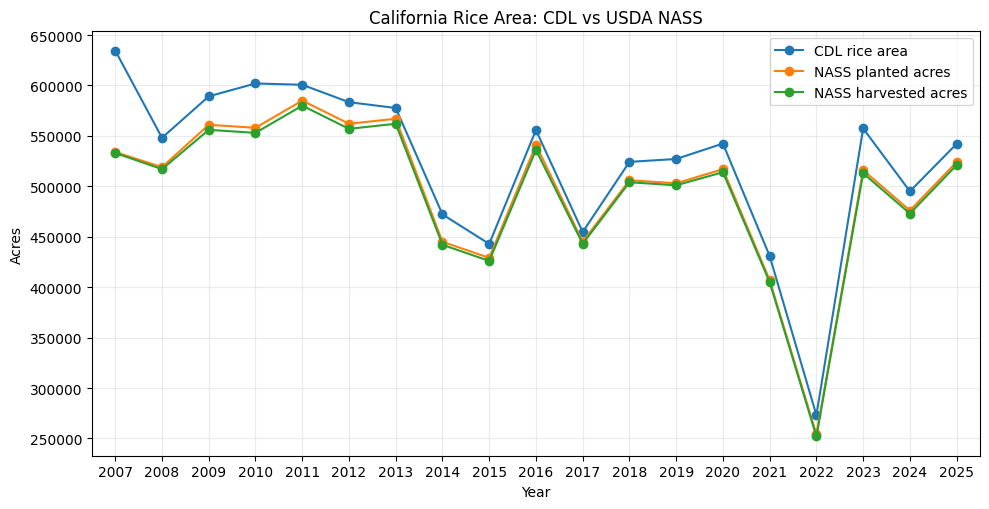

saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/04_nass_harvested_to_cdl_ratio.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/04_nass_harvested_to_cdl_ratio.svg


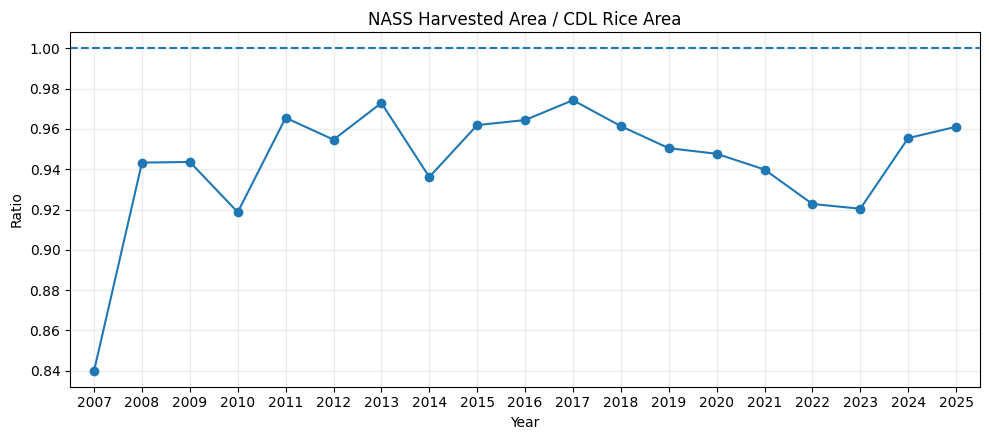

In [8]:
from matplotlib.ticker import MultipleLocator, StrMethodFormatter

display(area_qc)

# ============================================================
# Figure 03: CDL vs NASS area time series
# ============================================================

plt.figure(figsize=(10, 5.2))

plt.plot(
    area_qc["year"],
    area_qc["cdl_rice_area_acres"],
    marker="o",
    label="CDL rice area"
)

plt.plot(
    area_qc["year"],
    area_qc["nass_planted_acres"],
    marker="o",
    label="NASS planted acres"
)

plt.plot(
    area_qc["year"],
    area_qc["nass_harvested_acres"],
    marker="o",
    label="NASS harvested acres"
)

plt.title("California Rice Area: CDL vs USDA NASS")
plt.xlabel("Year")
plt.ylabel("Acres")
plt.legend()
plt.grid(alpha=0.25)

# Show integer years at one-year intervals on the x-axis
ax = plt.gca()
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:.0f}'))
ax.set_xlim(
    area_qc["year"].min() - 0.5,
    area_qc["year"].max() + 0.5
)

savefig("03_cdl_vs_nass_area_timeseries")
plt.show()


# ============================================================
# Figure 04: NASS harvested area / CDL rice area ratio
# ============================================================

if "nass_harvested_to_cdl_area_ratio" in area_qc.columns:

    plt.figure(figsize=(10, 4.5))

    plt.plot(
        area_qc["year"],
        area_qc["nass_harvested_to_cdl_area_ratio"],
        marker="o"
    )

    plt.axhline(
        1.0,
        linestyle="--"
    )

    plt.title("NASS Harvested Area / CDL Rice Area")
    plt.xlabel("Year")
    plt.ylabel("Ratio")
    plt.grid(alpha=0.25)

    # Show integer years at one-year intervals on the x-axis
    ax = plt.gca()
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.xaxis.set_major_formatter(StrMethodFormatter('{x:.0f}'))
    ax.set_xlim(
        area_qc["year"].min() - 0.5,
        area_qc["year"].max() + 0.5
    )

    savefig("04_nass_harvested_to_cdl_ratio")
    plt.show()


# ============================================================
# Save QC table
# ============================================================

area_qc.to_csv(
    TABLE_DIR / "02_nass_cdl_area_qc.csv",
    index=False
)


<details>
<summary><b>Result interpretation: CDL area versus NASS area</b></summary>

In `California Rice Area: CDL vs USDA NASS`, the CDL-derived rice area is slightly larger than NASS planted and harvested acreage, but the year-to-year patterns are closely aligned.

- All three series capture the 2014–2015 contraction, the 2016 recovery, the sharp 2021–2022 decline, and the 2023 rebound.
- From 2008 onward, the `NASS harvested / CDL rice area` ratio is generally stable at approximately **0.92–0.97**.
- 2007 is more of an outlier at approximately **0.84**, so it should be interpreted with additional caution.
- `reported_to_implied_production_ratio` is close to 1.0, indicating very strong internal consistency between NASS harvested area × yield and reported production.

Overall, the independently derived CDL rice area reproduces the major annual acreage variation reported by NASS and provides a useful cross-source QC check.

</details>


## 7. Correlation Between Seasonal Features and Yield

This is exploratory analysis and does not establish causality. Pearson correlation and Spearman rank correlation are calculated, and Pearson p-values are adjusted using the Benjamini–Hochberg false discovery rate (FDR) procedure.


,feature,n,pearson_r,pearson_p,spearman_rho,spearman_p,pearson_fdr_q,abs_pearson_r
22,tmean_c,19,0.616722,0.004916,0.609039,0.005645,0.046696,0.616722
17,swir1,19,0.605400,0.006019,0.550241,0.014646,0.046696,0.605400
26,cdl_rice_area_acres,19,-0.604582,0.006106,-0.634489,0.003523,0.046696,0.604582
21,tmax_c,19,0.595325,0.007163,0.529180,0.019816,0.046696,0.595325
18,swir2,19,0.579642,0.009291,0.503730,0.027886,0.046696,0.579642
16,red,19,0.570448,0.010759,0.511628,0.025147,0.046696,0.570448
0,blue,19,0.562863,0.012106,0.509873,0.025737,0.046696,0.562863
19,swir_1230,19,0.553103,0.014036,0.531812,0.019101,0.047371,0.553103
1,et,19,-0.533175,0.018738,-0.547609,0.015226,0.056215,0.533175
23,tmin_c,19,0.508362,0.026253,0.376481,0.112120,0.070883,0.508362


saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/05_seasonal_yield_correlations.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/05_seasonal_yield_correlations.svg


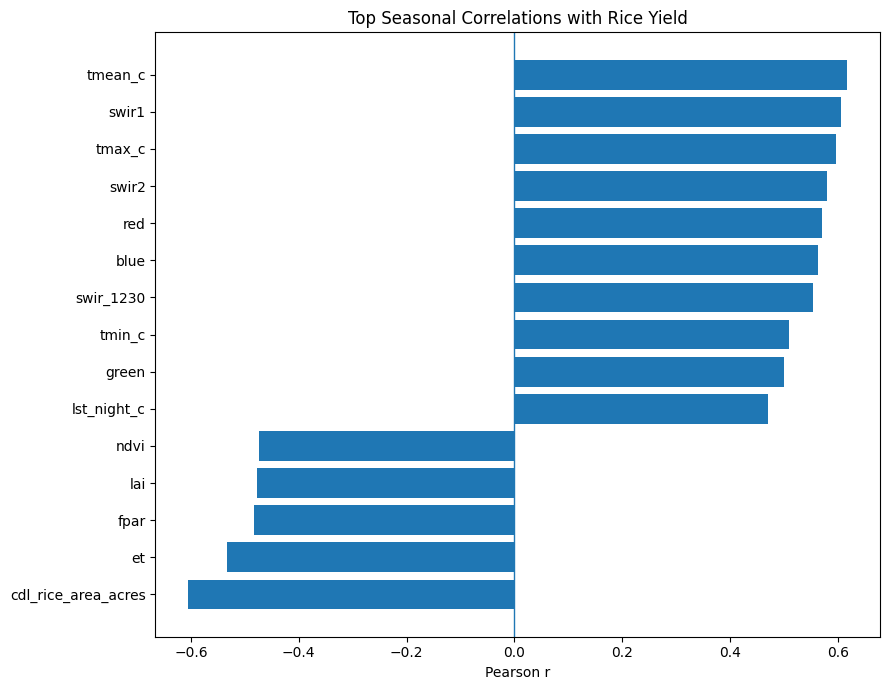

In [9]:
def benjamini_hochberg(pvalues):
    p = np.asarray(pvalues, dtype=float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order]
    q = ranked * n / np.arange(1, n+1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0, 1)
    out = np.empty_like(q)
    out[order] = q
    return out

def correlation_table(df, target, exclude=None, min_n=8):
    exclude = set(exclude or [])
    rows=[]
    for col in df.select_dtypes(include=np.number).columns:
        if col == target or col in exclude:
            continue
        x = pd.to_numeric(df[col], errors="coerce")
        y = pd.to_numeric(df[target], errors="coerce")
        ok = x.notna() & y.notna()
        n = int(ok.sum())
        if n < min_n or x[ok].nunique() < 2:
            continue
        pr, pp = pearsonr(x[ok], y[ok])
        sr, sp = spearmanr(x[ok], y[ok])
        rows.append({
            "feature": col, "n": n,
            "pearson_r": pr, "pearson_p": pp,
            "spearman_rho": sr, "spearman_p": sp,
        })
    out = pd.DataFrame(rows)
    if len(out):
        out["pearson_fdr_q"] = benjamini_hochberg(out["pearson_p"].values)
        out["abs_pearson_r"] = out["pearson_r"].abs()
        out = out.sort_values(["abs_pearson_r","feature"], ascending=[False,True])
    return out

seasonal_yield_corr = correlation_table(
    yearly,
    target="nass_yield_lb_acre",
    exclude=["year"] + TARGET_COLS + ["cdl_rice_pixels","cdl_rice_area_hectares"],
)

display(seasonal_yield_corr.head(20))
seasonal_yield_corr.to_csv(TABLE_DIR / "03_seasonal_yield_correlations.csv", index=False)

top = seasonal_yield_corr.head(15).sort_values("pearson_r")
plt.figure(figsize=(9,7))
plt.barh(top["feature"], top["pearson_r"])
plt.axvline(0, linewidth=1)
plt.title("Top Seasonal Correlations with Rice Yield")
plt.xlabel("Pearson r")
savefig("05_seasonal_yield_correlations")
plt.show()


<details>
<summary><b>Result interpretation: seasonal features and yield</b></summary>

With `correlation_table(..., min_n=8)`, `gpp_ntsg` has enough observations to be included in the correlation calculation, although it did not appear among the displayed top 20 features. `gpp_mod17` and `psn_net_mod17` have only five available years and are therefore excluded by the minimum-sample rule.

The strongest seasonal correlations included:

- `tmean_c`: r ≈ **+0.617**
- `swir1`: r ≈ **+0.605**
- `cdl_rice_area_acres`: r ≈ **−0.605**
- `tmax_c`: r ≈ **+0.595**
- `swir2`: r ≈ **+0.580**

Several of the strongest associations remain below q < 0.05 after FDR correction.

These are **associations, not causal effects**. For example, the negative relationship between `cdl_rice_area_acres` and yield indicates that statewide average yield tended to be higher in lower-acreage years, but multiple mechanisms could produce this pattern, including a selection effect in which planting becomes concentrated in better-performing fields during water-limited years.

NDVI, LAI, FPAR, and ET are negative in the seasonal aggregation. A simple seasonal average may therefore obscure growth-stage-specific relationships, which motivates the month-specific analysis.

</details>


## 8. Monthly Correlation Heatmap

The goal is not only to identify which features are associated with final annual yield, but also **which months carry the strongest signal**.


saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/06_monthly_yield_correlation_heatmap.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/06_monthly_yield_correlation_heatmap.svg


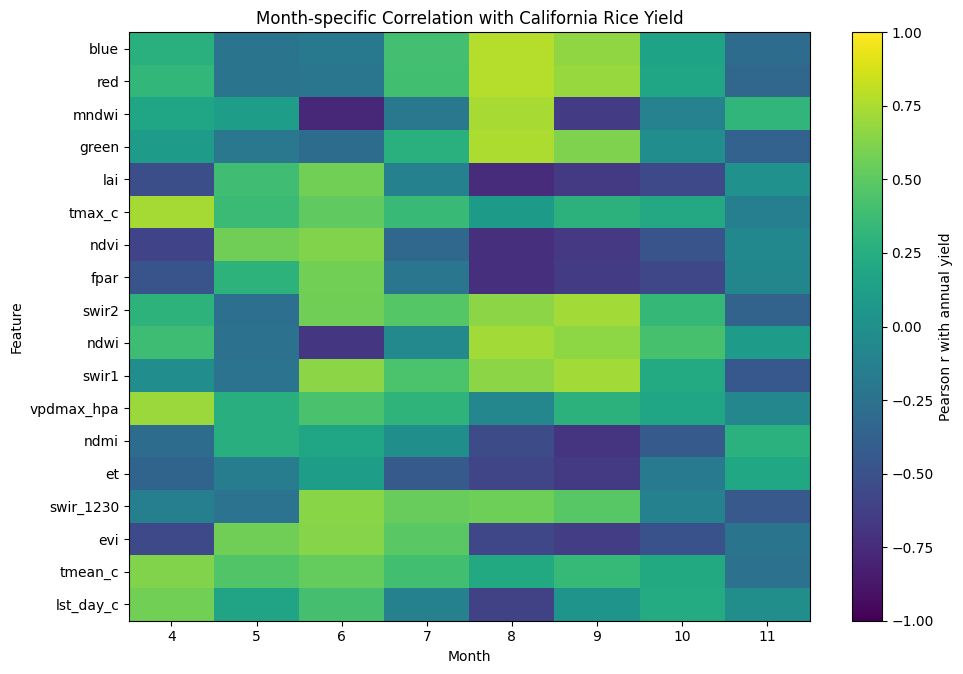

,feature,month,n,pearson_r,pearson_p,abs_r
4,blue,8,19,0.776661,0.000092,0.776661
148,red,8,19,0.776530,0.000092,0.776530
82,mndwi,6,19,-0.766806,0.000128,0.766806
52,green,8,19,0.756580,0.000178,0.756580
60,lai,8,19,-0.742420,0.000272,0.742420
84,mndwi,8,19,0.737209,0.000317,0.737209
184,tmax_c,4,19,0.733962,0.000347,0.733962
100,ndvi,8,19,-0.728333,0.000406,0.728333
28,fpar,8,19,-0.727755,0.000413,0.727755
165,swir2,9,19,0.721978,0.000483,0.721978


In [10]:
monthly_numeric = monthly.select_dtypes(include=np.number).columns.tolist()
monthly_feature_cols = [
    c for c in monthly_numeric
    if c not in ["year","month"] + TARGET_COLS + AREA_COLS
]

rows=[]
for feature in monthly_feature_cols:
    for m in EXPECTED_MONTHS:
        d = monthly[monthly["month"] == m]
        x = pd.to_numeric(d[feature], errors="coerce")
        y = pd.to_numeric(d["nass_yield_lb_acre"], errors="coerce")
        ok = x.notna() & y.notna()
        n = int(ok.sum())
        if n >= 8 and x[ok].nunique() >= 2:
            r,p = pearsonr(x[ok], y[ok])
        else:
            r,p = np.nan,np.nan
        rows.append({"feature":feature,"month":m,"n":n,"pearson_r":r,"pearson_p":p})

monthly_yield_corr = pd.DataFrame(rows)
monthly_yield_corr.to_csv(TABLE_DIR / "04_monthly_yield_correlations.csv", index=False)

rank = (
    monthly_yield_corr.assign(abs_r=monthly_yield_corr["pearson_r"].abs())
    .groupby("feature")["abs_r"].max().sort_values(ascending=False)
)
top_features = rank.head(min(18, len(rank))).index.tolist()
heat = (
    monthly_yield_corr[monthly_yield_corr["feature"].isin(top_features)]
    .pivot(index="feature", columns="month", values="pearson_r")
    .reindex(top_features)
)

plt.figure(figsize=(10, max(5,0.38*len(heat))))
im = plt.imshow(heat.values, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(im, label="Pearson r with annual yield")
plt.xticks(range(len(heat.columns)), [str(m) for m in heat.columns])
plt.yticks(range(len(heat.index)), heat.index)
plt.xlabel("Month")
plt.ylabel("Feature")
plt.title("Month-specific Correlation with California Rice Yield")
savefig("06_monthly_yield_correlation_heatmap")
plt.show()

display(
    monthly_yield_corr.assign(abs_r=monthly_yield_corr["pearson_r"].abs())
    .sort_values("abs_r", ascending=False).head(30)
)


<details>
<summary><b>Result interpretation: month-specific relationships with yield</b></summary>

Because the minimum sample size is `n >= 8`, `gpp_ntsg` can be evaluated in months with sufficient coverage, although it did not appear among the top 18 features shown in the heatmap.

The heatmap uses rows for features, columns for April–November, and color for the Pearson correlation between each monthly feature and final annual yield.

The strongest feature-month combinations included:

- August `blue`: r ≈ **+0.777**
- August `red`: r ≈ **+0.777**
- June `mndwi`: r ≈ **−0.767**
- August `green`: r ≈ **+0.757**
- August `lai`: r ≈ **−0.742**
- April `tmax_c`: r ≈ **+0.734**

The key result is that **the strength and even the sign of an association can change by month**. This means that not only what is observed, but also when it is observed, matters.

Strong relationships are especially visible for spectral and vegetation signals in August–September and for temperature/VPD conditions in April.

The p-values in this cell are not FDR-corrected across all month-feature tests, so individual combinations should be interpreted as exploratory candidates rather than definitive significance claims.

</details>


## 9. Exploratory Climate-Stress Score

This is not an official drought index. High VPD, high maximum temperature, and low precipitation are standardized in the direction of hotter and drier conditions and combined into a single exploratory score.


,year,exploratory_climate_stress_z,nass_yield_lb_acre
13,2020,1.258161,8720.0
15,2022,0.886318,8770.0
1,2008,0.880514,8320.0
7,2014,0.770747,8580.0
8,2015,0.556561,8890.0
6,2013,0.505826,8480.0
14,2021,0.391726,9050.0
10,2017,0.361724,8410.0
11,2018,0.046846,8620.0
17,2024,0.043384,8540.0


saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/07_exploratory_climate_stress.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/07_exploratory_climate_stress.svg


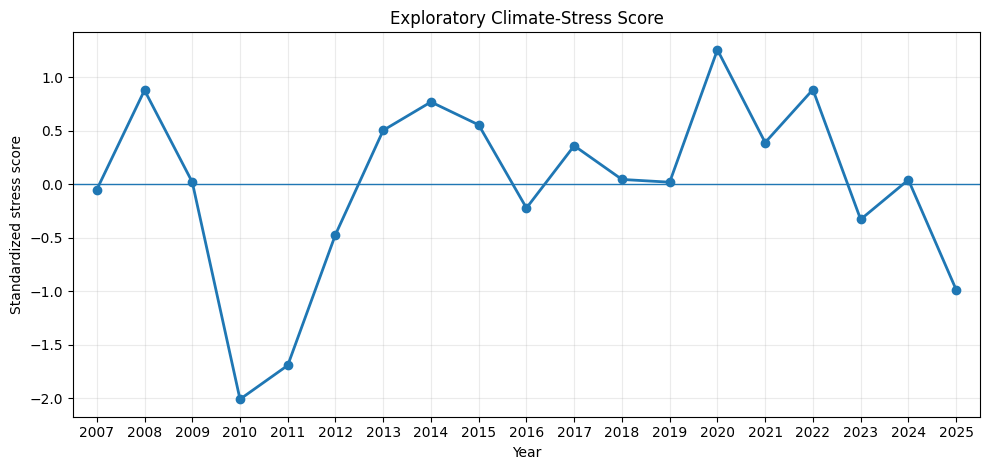

In [11]:
from matplotlib.ticker import MultipleLocator, StrMethodFormatter

stress_parts = []

if "vpdmax_hpa" in yearly.columns:
    stress_parts.append(
        pd.Series(
            zscore(yearly["vpdmax_hpa"], nan_policy="omit"),
            index=yearly.index
        )
    )

if "tmax_c" in yearly.columns:
    stress_parts.append(
        pd.Series(
            zscore(yearly["tmax_c"], nan_policy="omit"),
            index=yearly.index
        )
    )

if "ppt_mm" in yearly.columns:
    stress_parts.append(
        -pd.Series(
            zscore(yearly["ppt_mm"], nan_policy="omit"),
            index=yearly.index
        )
    )


if len(stress_parts) >= 2:

    stress = pd.concat(
        stress_parts,
        axis=1
    ).mean(axis=1)

    stress_df = pd.DataFrame({
        "year": yearly["year"],
        "exploratory_climate_stress_z": stress,
        "nass_yield_lb_acre": yearly["nass_yield_lb_acre"],
    })

    display(
        stress_df.sort_values(
            "exploratory_climate_stress_z",
            ascending=False
        )
    )

    stress_df.to_csv(
        TABLE_DIR / "05_exploratory_climate_stress.csv",
        index=False
    )

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(10, 4.8)
    )

    ax.plot(
        stress_df["year"],
        stress_df["exploratory_climate_stress_z"],
        marker="o",
        linewidth=2
    )

    ax.axhline(
        0,
        linewidth=1
    )

    ax.set_title(
        "Exploratory Climate-Stress Score"
    )

    ax.set_xlabel(
        "Year"
    )

    ax.set_ylabel(
        "Standardized stress score"
    )

    ax.grid(
        alpha=0.25
    )

    # --------------------------------------------------------
    # Show integer years only on the x-axis
    # --------------------------------------------------------

    ax.xaxis.set_major_locator(
        MultipleLocator(1)
    )

    ax.xaxis.set_major_formatter(
        StrMethodFormatter("{x:.0f}")
    )

    ax.set_xlim(
        stress_df["year"].min() - 0.5,
        stress_df["year"].max() + 0.5
    )

    savefig(
        "07_exploratory_climate_stress"
    )

    plt.show()

else:

    stress_df = None

    print(
        "Not enough VPD / Tmax / precipitation columns "
        "to build the score."
    )


<details>
<summary><b>Result interpretation: exploratory climate-stress score</b></summary>

This score is a custom exploratory index formed by standardizing and averaging `high VPD + high Tmax + low precipitation`. It is **not an official drought index**.

Years with high scores include:

- 2020: approximately **+1.26**
- 2022: approximately **+0.89**
- 2008: approximately **+0.88**
- 2014: approximately **+0.77**

Years with low scores include:

- 2010: approximately **−2.01**
- 2011: approximately **−1.69**
- 2025: approximately **−0.98**

A high stress score does not necessarily correspond to low yield. California rice is irrigated, and water limitation may sometimes appear more strongly as a **reduction in planted acreage** than as a collapse in statewide average yield.

</details>


# 10. Machine-Learning Design

The annual sample size is small (**n = 19**), so the following models are compared:

- Mean baseline: predicts the mean of the training years
- Year-trend baseline: predicts from a linear trend using year only
- Ridge: tunes the number of selected features and regularization strength inside each outer training fold
- Shallow Random Forest: an exploratory nonlinear model with constrained complexity

Predictor sets:

- `seasonal_env`
- `seasonal_env_area` (+ independently derived CDL rice area)
- `monthly_timing`
- `monthly_timing_area` (+ independently derived CDL rice area)

NASS outcome variables are excluded from the predictors.

`seasonal_complete` and `monthly_complete` retain only features available for all 19 years, so the incomplete GPP variables are excluded from the main ML analysis.


In [12]:
seasonal_candidates = [
    c for c in yearly.select_dtypes(include=np.number).columns
    if c not in ["year"] + TARGET_COLS + AREA_COLS
]
seasonal_complete = [
    c for c in seasonal_candidates
    if yearly[c].notna().all() and yearly[c].nunique() > 1
]

monthly_env = monthly[["year","month"] + monthly_feature_cols].copy()
monthly_pivot = monthly_env.set_index(["year","month"]).unstack("month")
monthly_pivot.columns = [
    f"{feature}_m{int(month_num):02d}"
    for feature, month_num in monthly_pivot.columns
]
monthly_pivot = monthly_pivot.reset_index().sort_values("year").reset_index(drop=True)

monthly_complete = [
    c for c in monthly_pivot.columns
    if c != "year" and monthly_pivot[c].notna().all() and monthly_pivot[c].nunique() > 1
]

model_base = yearly[["year","cdl_rice_area_acres"] + TARGET_COLS].copy()
monthly_model = model_base.merge(monthly_pivot, on="year", how="left", validate="1:1")

DATASETS = {
    "seasonal_env": (yearly, seasonal_complete),
    "seasonal_env_area": (yearly, seasonal_complete + ["cdl_rice_area_acres"]),
    "monthly_timing": (monthly_model, monthly_complete),
    "monthly_timing_area": (monthly_model, monthly_complete + ["cdl_rice_area_acres"]),
}

dataset_summary = pd.DataFrame([
    {
        "dataset": name,
        "rows": len(df),
        "predictors": len(cols),
        "missing_predictor_cells": int(df[cols].isna().sum().sum()),
    }
    for name,(df,cols) in DATASETS.items()
])
display(dataset_summary)
dataset_summary.to_csv(TABLE_DIR / "06_ml_dataset_summary.csv", index=False)

print("Seasonal complete predictors:", len(seasonal_complete))
print("Monthly timing complete predictors:", len(monthly_complete))


,dataset,rows,predictors,missing_predictor_cells
0,seasonal_env,19,25,0
1,seasonal_env_area,19,26,0
2,monthly_timing,19,200,0
3,monthly_timing_area,19,201,0


Seasonal complete predictors: 25
Monthly timing complete predictors: 200


<details>
<summary><b>Result interpretation: four ML input sets</b></summary>

The ML datasets contain:

- `seasonal_env`: 19 rows × **25** predictors
- `seasonal_env_area`: 19 rows × **26** predictors
- `monthly_timing`: 19 rows × **200** predictors
- `monthly_timing_area`: 19 rows × **201** predictors

All four have `missing_predictor_cells = 0`.

The monthly representation expands approximately 25 features across eight months, producing about 200 predictors for only 19 annual samples. Feature selection is therefore performed **inside each training fold**, so the held-out year is not used to choose predictors.

</details>


## 11. Nested Leave-One-Year-Out Functions

The outer loop completely holds out one year and predicts it without using that year in training. For Ridge, feature selection and alpha tuning are performed only within the remaining 18 training years.


In [13]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
    }

def valid_k_values(n_features):
    vals = [k for k in [3,5,8,10] if k < n_features] + ["all"]
    out=[]
    for v in vals:
        if v not in out:
            out.append(v)
    return out

def loocv_mean(X,y,years):
    loo=LeaveOneOut(); pred=np.full(len(y), np.nan)
    for tr,te in loo.split(X):
        m=DummyRegressor(strategy="mean").fit(X.iloc[tr], y.iloc[tr])
        pred[te]=m.predict(X.iloc[te])
    return pred, Counter()

def loocv_year_trend(years,y):
    Xy=np.asarray(years).reshape(-1,1); loo=LeaveOneOut(); pred=np.full(len(y),np.nan)
    for tr,te in loo.split(Xy):
        m=LinearRegression().fit(Xy[tr], y.iloc[tr])
        pred[te]=m.predict(Xy[te])
    return pred, Counter()

def loocv_ridge_nested(X,y):
    loo=LeaveOneOut(); pred=np.full(len(y),np.nan); counts=Counter()
    for tr,te in loo.split(X):
        Xtr,Xte=X.iloc[tr],X.iloc[te]; ytr=y.iloc[tr]
        pipe=Pipeline([
            ("scale",StandardScaler()),
            ("select",SelectKBest(f_regression)),
            ("model",Ridge()),
        ])
        inner=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
        search=GridSearchCV(
            pipe,
            {"select__k":valid_k_values(X.shape[1]),
             "model__alpha":[0.1,1.0,10.0,100.0]},
            scoring="neg_mean_squared_error",
            cv=inner,
            n_jobs=-1,
        )
        search.fit(Xtr,ytr)
        pred[te]=search.predict(Xte)
        support=search.best_estimator_.named_steps["select"].get_support()
        counts.update(X.columns[support].tolist())
    return pred,counts

def loocv_random_forest(X,y):
    loo=LeaveOneOut(); pred=np.full(len(y),np.nan); counts=Counter()
    k=min(5,X.shape[1])
    for tr,te in loo.split(X):
        pipe=Pipeline([
            ("select",SelectKBest(f_regression,k=k)),
            ("model",RandomForestRegressor(
                n_estimators=400,max_depth=3,min_samples_leaf=2,
                max_features="sqrt",random_state=RANDOM_STATE,n_jobs=-1,
            )),
        ])
        pipe.fit(X.iloc[tr], y.iloc[tr])
        pred[te]=pipe.predict(X.iloc[te])
        support=pipe.named_steps["select"].get_support()
        counts.update(X.columns[support].tolist())
    return pred,counts

def run_cv_suite(df,predictor_cols,target,dataset_name):
    X=df[predictor_cols].astype(float).copy()
    y=pd.to_numeric(df[target],errors="raise").astype(float)
    years=df["year"].astype(int).to_numpy()
    assert X.notna().all().all()

    runners={
        "Mean baseline":lambda:loocv_mean(X,y,years),
        "Year trend":lambda:loocv_year_trend(years,y),
        "Ridge nested":lambda:loocv_ridge_nested(X,y),
        "Random forest":lambda:loocv_random_forest(X,y),
    }

    summary=[]; preds=[]; stability=[]
    for model_name,runner in runners.items():
        print(target,"|",dataset_name,"|",model_name)
        pred,counts=runner()
        summary.append({
            "target":target,"dataset":dataset_name,"model":model_name,
            "n":len(y),"n_predictors":X.shape[1],
            **regression_metrics(y.values,pred),
        })
        for yr,a,p in zip(years,y.values,pred):
            preds.append({
                "target":target,"dataset":dataset_name,"model":model_name,
                "year":int(yr),"actual":float(a),"predicted":float(p),
                "residual":float(a-p),
            })
        for feature,count in counts.items():
            stability.append({
                "target":target,"dataset":dataset_name,"model":model_name,
                "feature":feature,"selected_outer_folds":int(count),
                "selection_fraction":count/len(y),
            })
    return pd.DataFrame(summary),pd.DataFrame(preds),pd.DataFrame(stability)

def run_target_across_datasets(target):
    ss=[]; pp=[]; st=[]
    for name,(df,cols) in DATASETS.items():
        s,p,t=run_cv_suite(df,cols,target,name)
        ss.append(s); pp.append(p)
        if len(t): st.append(t)
    summary=pd.concat(ss,ignore_index=True)
    preds=pd.concat(pp,ignore_index=True)
    stability=pd.concat(st,ignore_index=True) if st else pd.DataFrame()

    base=summary[summary["model"]=="Mean baseline"].set_index("dataset")["RMSE"].to_dict()
    summary["RMSE_skill_vs_mean"]=summary.apply(
        lambda r:1.0-r["RMSE"]/base[r["dataset"]],axis=1
    )
    return summary,preds,stability


<details>
<summary><b>Method note: Why use nested LOOCV?</b></summary>

Each year is held out once, so all 19 final predictions are out-of-sample.

- Mean baseline: mean of the remaining 18 years
- Year trend: linear regression using year only
- Ridge: uses an additional 5-fold CV within the remaining 18 years to select `k` and `alpha`
- Random Forest: runs `SelectKBest(k=5)` using only the training data in each outer fold, then fits a shallow forest with those five features

This design prevents the held-out year's target from influencing feature selection.

</details>


## 12. Yield Prediction

Compare the primary target, `nass_yield_lb_acre`, across combinations of seasonal aggregation, monthly timing, inclusion or exclusion of CDL rice area, and model type.


In [14]:
yield_summary,yield_predictions,yield_stability = run_target_across_datasets(
    "nass_yield_lb_acre"
)
yield_summary = yield_summary.sort_values(["RMSE","MAE"]).reset_index(drop=True)
display(yield_summary)

yield_summary.to_csv(TABLE_DIR / "07_yield_cv_results.csv",index=False)
yield_predictions.to_csv(TABLE_DIR / "08_yield_cv_predictions.csv",index=False)
yield_stability.to_csv(TABLE_DIR / "09_yield_feature_selection_stability.csv",index=False)


nass_yield_lb_acre | seasonal_env | Mean baseline
nass_yield_lb_acre | seasonal_env | Year trend
nass_yield_lb_acre | seasonal_env | Ridge nested
nass_yield_lb_acre | seasonal_env | Random forest
nass_yield_lb_acre | seasonal_env_area | Mean baseline
nass_yield_lb_acre | seasonal_env_area | Year trend
nass_yield_lb_acre | seasonal_env_area | Ridge nested
nass_yield_lb_acre | seasonal_env_area | Random forest
nass_yield_lb_acre | monthly_timing | Mean baseline
nass_yield_lb_acre | monthly_timing | Year trend
nass_yield_lb_acre | monthly_timing | Ridge nested
nass_yield_lb_acre | monthly_timing | Random forest
nass_yield_lb_acre | monthly_timing_area | Mean baseline
nass_yield_lb_acre | monthly_timing_area | Year trend
nass_yield_lb_acre | monthly_timing_area | Ridge nested
nass_yield_lb_acre | monthly_timing_area | Random forest


,target,dataset,model,n,n_predictors,MAE,RMSE,R2,RMSE_skill_vs_mean
0,nass_yield_lb_acre,monthly_timing_area,Random forest,19,201,165.730065,211.800411,0.303233,0.209207
1,nass_yield_lb_acre,monthly_timing,Random forest,19,200,165.730065,211.800411,0.303233,0.209207
2,nass_yield_lb_acre,monthly_timing_area,Ridge nested,19,201,187.282998,235.365538,0.139562,0.121223
3,nass_yield_lb_acre,seasonal_env_area,Random forest,19,26,201.365700,239.517013,0.108941,0.105723
4,nass_yield_lb_acre,monthly_timing,Ridge nested,19,200,195.255551,241.751595,0.092237,0.097380
5,nass_yield_lb_acre,seasonal_env,Year trend,19,25,203.083476,243.975187,0.075461,0.089078
6,nass_yield_lb_acre,seasonal_env_area,Year trend,19,26,203.083476,243.975187,0.075461,0.089078
7,nass_yield_lb_acre,monthly_timing,Year trend,19,200,203.083476,243.975187,0.075461,0.089078
8,nass_yield_lb_acre,monthly_timing_area,Year trend,19,201,203.083476,243.975187,0.075461,0.089078
9,nass_yield_lb_acre,seasonal_env,Random forest,19,25,203.966479,244.289279,0.073079,0.087905


<details>
<summary><b>Result interpretation: yield model comparison</b></summary>

The best exploratory yield model was **`monthly_timing_area + Random Forest`**.

- MAE ≈ **165.7 lb/acre**
- RMSE ≈ **211.8 lb/acre**
- R² ≈ **0.303**
- RMSE skill versus the mean baseline ≈ **+20.9%**

`monthly_timing + Random Forest` produced the same RMSE, so adding CDL area did not improve Random Forest yield prediction.

Key comparison:

- Seasonal Random Forest: RMSE ≈ 244
- Monthly Random Forest: RMSE ≈ 212
- Year trend: RMSE ≈ 244
- Mean baseline: RMSE ≈ 268

Preserving **monthly timing information** improved prediction relative to seasonal averages and also outperformed a simple year trend, suggesting that the satellite and climate features contain additional predictive signal.

Because the annual sample size is only n=19, these results should be treated as exploratory rather than as evidence of an operational high-accuracy forecasting model.

</details>


saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/08_yield_model_rmse_comparison.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/08_yield_model_rmse_comparison.svg


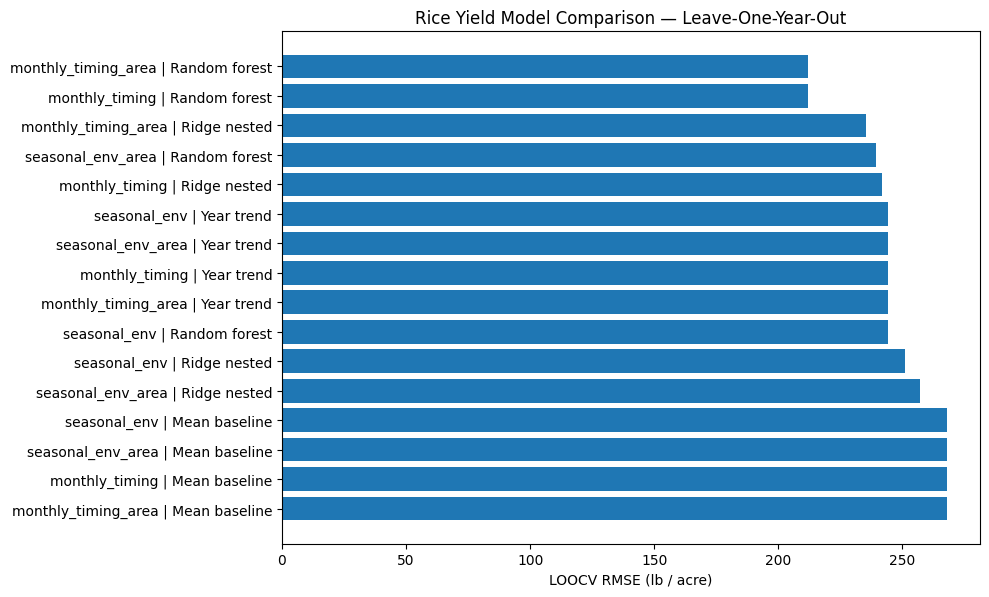

saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/09_yield_observed_vs_loocv_predicted.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/09_yield_observed_vs_loocv_predicted.svg


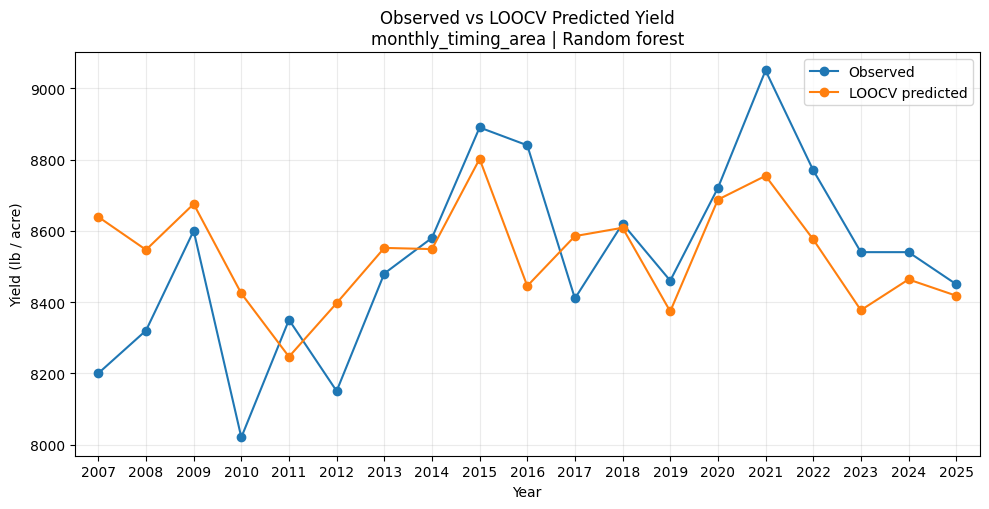

,target,dataset,model,n,n_predictors,MAE,RMSE,R2,RMSE_skill_vs_mean
0,nass_yield_lb_acre,monthly_timing_area,Random forest,19,201,165.730065,211.800411,0.303233,0.209207


In [15]:
from matplotlib.ticker import MultipleLocator, StrMethodFormatter

plot_df = yield_summary.sort_values("RMSE")
labels = plot_df["dataset"] + " | " + plot_df["model"]

plt.figure(figsize=(10, max(6, 0.38 * len(plot_df))))
plt.barh(labels, plot_df["RMSE"])
plt.xlabel("LOOCV RMSE (lb / acre)")
plt.title("Rice Yield Model Comparison — Leave-One-Year-Out")
plt.gca().invert_yaxis()
savefig("08_yield_model_rmse_comparison")
plt.show()

candidate = yield_summary[
    ~yield_summary["model"].isin(["Mean baseline", "Year trend"])
].sort_values("RMSE").iloc[0]

best_yield_dataset = candidate["dataset"]
best_yield_model = candidate["model"]

bp = yield_predictions[
    (yield_predictions["dataset"] == best_yield_dataset) &
    (yield_predictions["model"] == best_yield_model)
].sort_values("year")

# Ensure year is numeric
bp["year"] = pd.to_numeric(bp["year"])

plt.figure(figsize=(10, 5.2))
plt.plot(bp["year"], bp["actual"], marker="o", label="Observed")
plt.plot(bp["year"], bp["predicted"], marker="o", label="LOOCV predicted")
plt.xlabel("Year")
plt.ylabel("Yield (lb / acre)")
plt.title(f"Observed vs LOOCV Predicted Yield\n{best_yield_dataset} | {best_yield_model}")
plt.legend()
plt.grid(alpha=0.25)

ax = plt.gca()
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:.0f}"))
ax.set_xlim(bp["year"].min() - 0.5, bp["year"].max() + 0.5)

savefig("09_yield_observed_vs_loocv_predicted")
plt.show()

display(candidate.to_frame().T)


<details>
<summary><b>Result interpretation: observed vs. LOOCV-predicted yield</b></summary>

The observed NASS yield is compared with the **LOOCV prediction generated without using that year for training**.

The model follows some of the year-to-year variation, but extreme years such as the low value in 2010 and the high value in 2021 are pulled toward the center. This is expected behavior for a shallow Random Forest trained on a very small annual sample.

The important point is that the predicted series is not an in-sample fit. Every point is a held-out prediction, so the plot reflects out-of-sample performance across years.

</details>


## 13. Stability of Yield Feature Selection

Features that are repeatedly selected as the held-out year changes are less dependent on any single year and can be considered more stable candidates.


,target,dataset,model,feature,selected_outer_folds,selection_fraction
481,nass_yield_lb_acre,monthly_timing_area,Random forest,blue_m08,19,1.000000
482,nass_yield_lb_acre,monthly_timing_area,Random forest,green_m08,19,1.000000
485,nass_yield_lb_acre,monthly_timing_area,Random forest,red_m08,19,1.000000
487,nass_yield_lb_acre,monthly_timing_area,Random forest,mndwi_m06,17,0.894737
486,nass_yield_lb_acre,monthly_timing_area,Random forest,lai_m08,8,0.421053
488,nass_yield_lb_acre,monthly_timing_area,Random forest,mndwi_m08,4,0.210526
490,nass_yield_lb_acre,monthly_timing_area,Random forest,tmax_c_m04,4,0.210526
489,nass_yield_lb_acre,monthly_timing_area,Random forest,lst_day_c_m08,1,0.052632
483,nass_yield_lb_acre,monthly_timing_area,Random forest,ndvi_m08,1,0.052632
484,nass_yield_lb_acre,monthly_timing_area,Random forest,ndwi_m08,1,0.052632


saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/10_yield_feature_selection_stability.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/10_yield_feature_selection_stability.svg


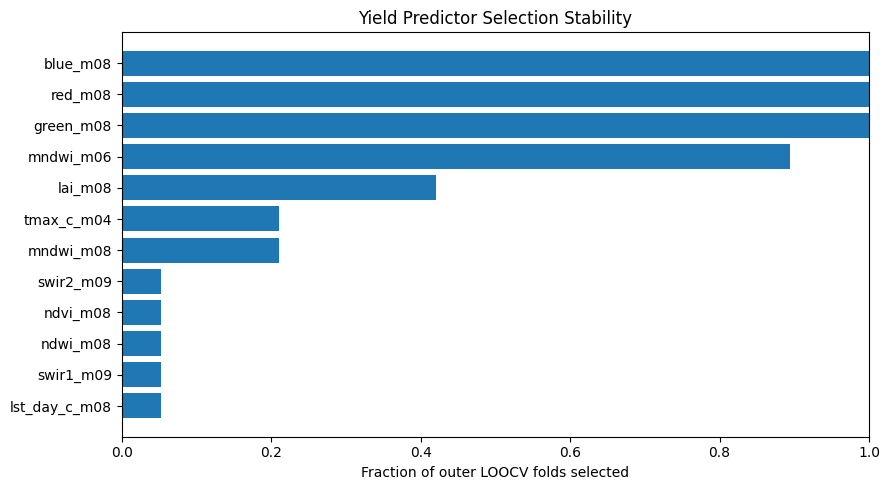

In [16]:
if len(yield_stability):
    best_stab=yield_stability[
        (yield_stability["dataset"]==best_yield_dataset) &
        (yield_stability["model"]==best_yield_model)
    ].sort_values(["selected_outer_folds","feature"],ascending=[False,True])

    display(best_stab.head(25))
    top_stab=best_stab.head(20).sort_values("selection_fraction")
    plt.figure(figsize=(9,max(5,0.35*len(top_stab))))
    plt.barh(top_stab["feature"],top_stab["selection_fraction"])
    plt.xlim(0,1)
    plt.xlabel("Fraction of outer LOOCV folds selected")
    plt.title("Yield Predictor Selection Stability")
    savefig("10_yield_feature_selection_stability")
    plt.show()


<details>
<summary><b>Result interpretation: yield predictor selection stability</b></summary>

For each outer LOOCV fold, `SelectKBest(k=5)` is applied before the Random Forest, and the selected features are counted across folds.

The most stable features were:

- `blue_m08`: **19/19**
- `green_m08`: **19/19**
- `red_m08`: **19/19**
- `mndwi_m06`: **17/19**
- `lai_m08`: **8/19**

Thus, **August visible-band reflectance (blue/green/red) and June MNDWI** were repeatedly selected even as the held-out year changed.

This is selection stability before model fitting, not Random Forest feature importance. Because blue, red, and green may be strongly correlated, they are more safely interpreted as a common **August visible-spectrum signal** rather than as three independent phenomena.

</details>


## 14. Production Prediction

For predictor sets ending in `*_area`, add **rice area independently derived from CDL**, not NASS acreage. NASS planted and harvested acreage remain excluded from the predictors.


In [17]:
production_summary,production_predictions,production_stability = run_target_across_datasets(
    "nass_production_cwt"
)
production_summary=production_summary.sort_values(["RMSE","MAE"]).reset_index(drop=True)
display(production_summary)

production_summary.to_csv(TABLE_DIR / "10_production_cv_results.csv",index=False)
production_predictions.to_csv(TABLE_DIR / "11_production_cv_predictions.csv",index=False)
production_stability.to_csv(TABLE_DIR / "12_production_feature_selection_stability.csv",index=False)


nass_production_cwt | seasonal_env | Mean baseline
nass_production_cwt | seasonal_env | Year trend
nass_production_cwt | seasonal_env | Ridge nested
nass_production_cwt | seasonal_env | Random forest
nass_production_cwt | seasonal_env_area | Mean baseline
nass_production_cwt | seasonal_env_area | Year trend
nass_production_cwt | seasonal_env_area | Ridge nested
nass_production_cwt | seasonal_env_area | Random forest
nass_production_cwt | monthly_timing | Mean baseline
nass_production_cwt | monthly_timing | Year trend
nass_production_cwt | monthly_timing | Ridge nested
nass_production_cwt | monthly_timing | Random forest
nass_production_cwt | monthly_timing_area | Mean baseline
nass_production_cwt | monthly_timing_area | Year trend
nass_production_cwt | monthly_timing_area | Ridge nested
nass_production_cwt | monthly_timing_area | Random forest


,target,dataset,model,n,n_predictors,MAE,RMSE,R2,RMSE_skill_vs_mean
0,nass_production_cwt,seasonal_env_area,Ridge nested,19,26,1.836370e+06,2.588970e+06,0.806141,0.582879
1,nass_production_cwt,seasonal_env_area,Random forest,19,26,2.944701e+06,4.466049e+06,0.423128,0.280454
2,nass_production_cwt,monthly_timing_area,Ridge nested,19,201,2.908407e+06,4.518237e+06,0.409567,0.272046
3,nass_production_cwt,monthly_timing_area,Random forest,19,201,3.131290e+06,4.737807e+06,0.350787,0.236670
4,nass_production_cwt,seasonal_env,Random forest,19,25,3.388058e+06,4.944262e+06,0.292974,0.203407
5,nass_production_cwt,seasonal_env,Ridge nested,19,25,3.429209e+06,5.061936e+06,0.258919,0.184448
6,nass_production_cwt,monthly_timing,Ridge nested,19,200,3.709450e+06,5.167512e+06,0.227684,0.167438
7,nass_production_cwt,monthly_timing,Random forest,19,200,3.906057e+06,5.414794e+06,0.151999,0.127597
8,nass_production_cwt,seasonal_env,Year trend,19,25,4.631191e+06,6.055050e+06,-0.060395,0.024443
9,nass_production_cwt,seasonal_env_area,Year trend,19,26,4.631191e+06,6.055050e+06,-0.060395,0.024443


<details>
<summary><b>Result interpretation: production model comparison</b></summary>

The best production model was **`seasonal_env_area + Ridge nested`**.

- MAE ≈ **1.84 million CWT**
- RMSE ≈ **2.59 million CWT**
- R² ≈ **0.806**
- RMSE skill versus the mean baseline ≈ **+58.3%**

The effect of including area is especially strong:

- `seasonal_env + Ridge`: R² ≈ 0.259, RMSE ≈ 5.06M
- `seasonal_env_area + Ridge`: R² ≈ 0.806, RMSE ≈ 2.59M

Production prediction improved substantially when the independently derived CDL rice area was added to the satellite and climate features.

Yield benefited most from monthly timing, whereas production was best modeled with **seasonal environment + acreage** using Ridge. This is consistent with the basic structure of Production ≈ Area × Yield.

</details>


saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/11_production_model_rmse_comparison.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/11_production_model_rmse_comparison.svg


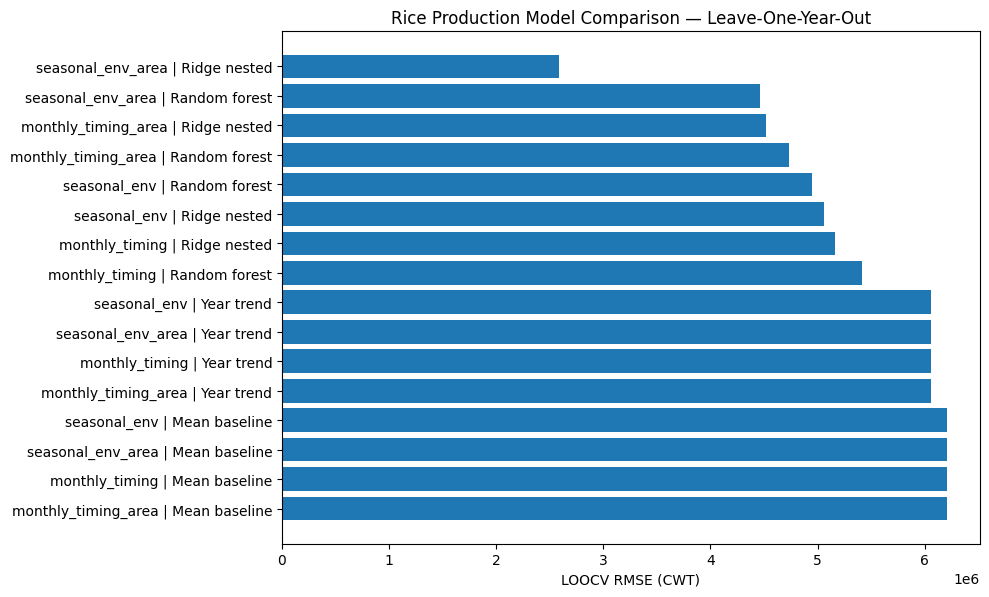

saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/12_production_observed_vs_loocv_predicted.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/12_production_observed_vs_loocv_predicted.svg


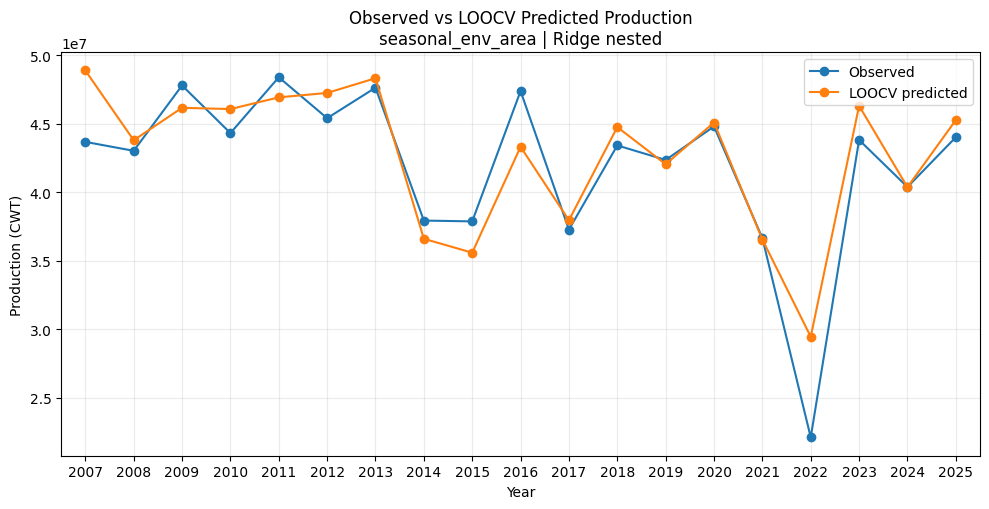

,target,dataset,model,n,n_predictors,MAE,RMSE,R2,RMSE_skill_vs_mean
0,nass_production_cwt,seasonal_env_area,Ridge nested,19,26,1836370.013018,2588969.792411,0.806141,0.582879


In [18]:
from matplotlib.ticker import MultipleLocator, StrMethodFormatter

plot_df = production_summary.sort_values("RMSE")
labels = plot_df["dataset"] + " | " + plot_df["model"]

plt.figure(figsize=(10, max(6, 0.38 * len(plot_df))))
plt.barh(labels, plot_df["RMSE"])
plt.xlabel("LOOCV RMSE (CWT)")
plt.title("Rice Production Model Comparison — Leave-One-Year-Out")
plt.gca().invert_yaxis()
savefig("11_production_model_rmse_comparison")
plt.show()

candidate = production_summary[
    ~production_summary["model"].isin(["Mean baseline", "Year trend"])
].sort_values("RMSE").iloc[0]

best_prod_dataset = candidate["dataset"]
best_prod_model = candidate["model"]

bp = production_predictions[
    (production_predictions["dataset"] == best_prod_dataset) &
    (production_predictions["model"] == best_prod_model)
].sort_values("year")

# Ensure year is numeric
bp["year"] = pd.to_numeric(bp["year"])

plt.figure(figsize=(10, 5.2))
plt.plot(bp["year"], bp["actual"], marker="o", label="Observed")
plt.plot(bp["year"], bp["predicted"], marker="o", label="LOOCV predicted")
plt.xlabel("Year")
plt.ylabel("Production (CWT)")
plt.title(
    f"Observed vs LOOCV Predicted Production\n"
    f"{best_prod_dataset} | {best_prod_model}"
)
plt.legend()
plt.grid(alpha=0.25)

# Display years as integers
ax = plt.gca()
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:.0f}"))
ax.set_xlim(
    bp["year"].min() - 0.5,
    bp["year"].max() + 0.5
)

savefig("12_production_observed_vs_loocv_predicted")
plt.show()

display(candidate.to_frame().T)


<details>
<summary><b>Result interpretation: observed vs. LOOCV-predicted production</b></summary>

Observed NASS production is compared with predictions generated by completely holding out each year in turn.

The model follows much of the annual variation, but it overpredicts the **extreme production decline in 2022**. This illustrates the difficulty of extrapolating an unusually large acreage contraction when the target year is excluded from training.

Even so, overall LOOCV R² is approximately 0.81, and RMSE improves by about 58% relative to the mean baseline.

This model includes the same year's CDL-derived rice area. It should therefore be interpreted as **retrospective prediction / estimation using observed annual area and environmental conditions**, rather than as an early-season forecast made before acreage is known.

</details>


## 15. Descriptive Final Ridge Fit

Model performance is evaluated using the held-out-year LOOCV results above. Here, Ridge is fit to all 19 years only to inspect the direction and magnitude of standardized coefficients **descriptively**.

GPP variables are not used in this fit.


Dataset: monthly_timing_area
Best full-data descriptive parameters: {'model__alpha': 10.0, 'select__k': 5}


,feature,standardized_ridge_coefficient,abs_coefficient
3,mndwi_m06,-53.738376,53.738376
0,blue_m08,40.305514,40.305514
4,red_m08,37.662039,37.662039
1,green_m08,31.283310,31.283310
2,lai_m08,-26.023010,26.023010


saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/13_descriptive_ridge_yield_coefficients.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/13_descriptive_ridge_yield_coefficients.svg


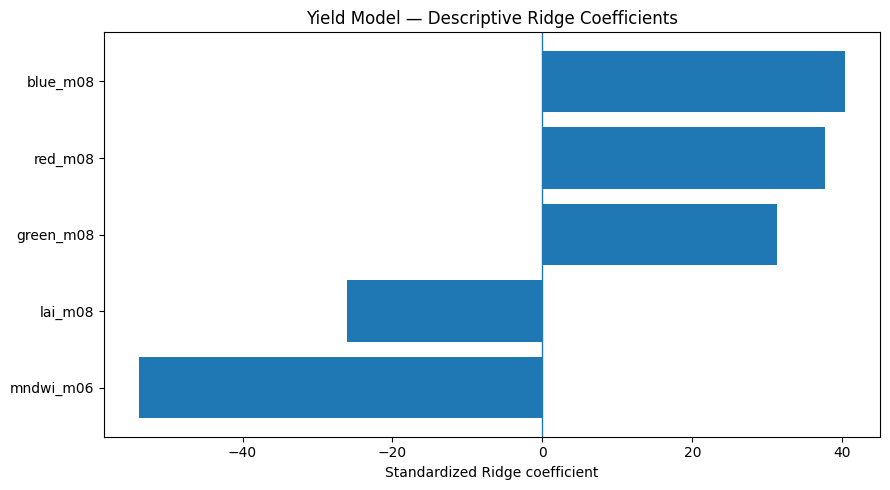

In [19]:
def fit_descriptive_ridge(df,predictor_cols,target):
    X=df[predictor_cols].astype(float)
    y=df[target].astype(float)
    pipe=Pipeline([
        ("scale",StandardScaler()),
        ("select",SelectKBest(f_regression)),
        ("model",Ridge()),
    ])
    search=GridSearchCV(
        pipe,
        {"select__k":valid_k_values(X.shape[1]),
         "model__alpha":[0.1,1.0,10.0,100.0]},
        scoring="neg_mean_squared_error",
        cv=LeaveOneOut(),
        n_jobs=-1,
    )
    search.fit(X,y)
    best=search.best_estimator_
    support=best.named_steps["select"].get_support()
    selected=X.columns[support]
    coefs=best.named_steps["model"].coef_
    coef_df=pd.DataFrame({
        "feature":selected,
        "standardized_ridge_coefficient":coefs,
        "abs_coefficient":np.abs(coefs),
    }).sort_values("abs_coefficient",ascending=False)
    return search.best_params_,coef_df

best_ridge_row=yield_summary[
    yield_summary["model"]=="Ridge nested"
].sort_values("RMSE").iloc[0]

ridge_dataset=best_ridge_row["dataset"]
ridge_df,ridge_cols=DATASETS[ridge_dataset]
ridge_params,ridge_coef=fit_descriptive_ridge(
    ridge_df,ridge_cols,"nass_yield_lb_acre"
)

print("Dataset:",ridge_dataset)
print("Best full-data descriptive parameters:",ridge_params)
display(ridge_coef)

ridge_coef.to_csv(TABLE_DIR / "13_descriptive_ridge_yield_coefficients.csv",index=False)

plot_coef=ridge_coef.head(20).sort_values("standardized_ridge_coefficient")
plt.figure(figsize=(9,max(5,0.38*len(plot_coef))))
plt.barh(plot_coef["feature"],plot_coef["standardized_ridge_coefficient"])
plt.axvline(0,linewidth=1)
plt.xlabel("Standardized Ridge coefficient")
plt.title("Yield Model — Descriptive Ridge Coefficients")
savefig("13_descriptive_ridge_yield_coefficients")
plt.show()


<details>
<summary><b>Result interpretation: descriptive Ridge coefficients</b></summary>

The five features selected in the full 19-year descriptive Ridge fit and their standardized coefficients were:

- `mndwi_m06`: **−53.74**
- `blue_m08`: **+40.31**
- `red_m08`: **+37.66**
- `green_m08`: **+31.28**
- `lai_m08`: **−26.02**

This is consistent with the earlier correlation and selection-stability results: **June water-related signals and August visible/canopy signals** repeatedly emerge as important candidates.

The coefficients indicate the direction of yield change associated with a one-standard-deviation change in each selected predictor. Because predictors can be strongly correlated, coefficient magnitude should not be treated as a direct feature-importance ranking. This fit uses all 19 years for descriptive interpretation; predictive performance is evaluated with the LOOCV results above.

</details>


## 16. Save a Compact Analysis Summary

No new analysis is performed here. The best yield and production models, analysis period, validation method, and scientific caveats are collected into a JSON summary.


In [ ]:
best_yield = yield_summary[
    ~yield_summary["model"].isin(["Mean baseline","Year trend"])
].sort_values("RMSE").iloc[0].to_dict()

best_production = production_summary[
    ~production_summary["model"].isin(["Mean baseline","Year trend"])
].sort_values("RMSE").iloc[0].to_dict()

analysis_summary = {
    "analysis_years":[2007,2025],
    "annual_n":19,
    "months":list(range(4,12)),
    "validation":"outer leave-one-out cross-validation by year",
    "primary_target":"nass_yield_lb_acre",
    "secondary_target":"nass_production_cwt",
    "best_exploratory_yield_model":best_yield,
    "best_exploratory_production_model":best_production,
    "guardrails":[
        "No NASS outcome/context variables used as predictors.",
        "No interpolation between UMT/NTSG GPP and MOD17 GPP.",
        "Primary full-period ML uses complete-coverage predictors.",
        "Results are exploratory because annual n=19.",
        "Exploratory climate-stress score is not an official drought index.",
    ],
}

summary_path=OUTPUT_ROOT / "analysis_summary.json"
summary_path.write_text(
    json.dumps(analysis_summary,indent=2,ensure_ascii=False,default=float),
    encoding="utf-8",
)
print(summary_path)
print(json.dumps(analysis_summary,indent=2,ensure_ascii=False,default=float))


/content/drive/MyDrive/YOUR_PROJECT_FOLDER/analysis_outputs/analysis_summary.json
{
  "analysis_years": [
    2007,
    2025
  ],
  "annual_n": 19,
  "months": [
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11
  ],
  "validation": "outer leave-one-out cross-validation by year",
  "primary_target": "nass_yield_lb_acre",
  "secondary_target": "nass_production_cwt",
  "best_exploratory_yield_model": {
    "target": "nass_yield_lb_acre",
    "dataset": "monthly_timing",
    "model": "Random forest",
    "n": 19,
    "n_predictors": 200,
    "MAE": 165.7300654572032,
    "RMSE": 211.80041141231032,
    "R2": 0.3032334328772468,
    "RMSE_skill_vs_mean": 0.20920747395672368
  },
  "best_exploratory_production_model": {
    "target": "nass_production_cwt",
    "dataset": "seasonal_env_area",
    "model": "Ridge nested",
    "n": 19,
    "n_predictors": 26,
    "MAE": 1836370.0130180449,
    "RMSE": 2588969.7924108184,
    "R2": 0.8061408713565859,
    "RMSE_skill_vs_mean": 0.58287902

<details>
<summary><b>Result interpretation: analysis summary</b></summary>

This JSON is a compact summary of the notebook rather than a new analysis.

Main results:

- Yield: `monthly_timing_area + Random Forest`
  - RMSE ≈ **211.8 lb/acre**
  - R² ≈ **0.303**
  - Skill versus the mean baseline ≈ **20.9%**
- Production: `seasonal_env_area + Ridge nested`
  - RMSE ≈ **2.59M CWT**
  - R² ≈ **0.806**
  - Skill versus the mean baseline ≈ **58.3%**

A central analytical contrast is that **monthly timing mattered most for yield, while rice area was especially important for production**.

</details>


## 17. Export Analysis Outputs as a ZIP Archive

This cell only packages figures, tables, and JSON files under `analysis_outputs/` into a ZIP archive. It does not modify the original `processed/` data.


In [ ]:
zip_path = shutil.make_archive(
    str(PROJECT_ROOT / "california_rice_analysis_outputs"),
    "zip",
    root_dir=OUTPUT_ROOT,
)
print("Created:",zip_path)
print("Figures:",len(list(FIG_DIR.glob("*.png"))),"PNG")
print("Tables :",len(list(TABLE_DIR.glob("*.csv"))),"CSV")


Created: /content/drive/MyDrive/YOUR_PROJECT_FOLDER/california_rice_analysis_outputs.zip
Figures: 24 PNG
Tables : 16 CSV


<details>
<summary><b>Result interpretation: ZIP output</b></summary>

The analysis outputs are collected into a single ZIP archive. The current run contains **15 PNG / 14 CSV** files.

This cell only organizes files; it does not perform additional statistical analysis or model fitting.

</details>


# Interpretation checklist

1. Compare the models against both the mean baseline and the year-trend baseline.
2. Prioritize held-out-year predictive performance over the appearance of a full-data fit.
3. Positive LOOCV skill indicates predictive signal, not causality.
4. Use the month-specific analysis to assess the role of **timing**.
5. Keep UMT/NTSG GPP and MOD17 GPP as separate series.
6. Treat the climate-stress score as **exploratory and not an official drought index**.
7. Treat ML as the final analytical layer built on a reproducible GIS + satellite + climate + NASS workflow.


# Overall conclusions

<details open>
<summary><b>Main findings</b></summary>

1. **CDL-derived rice area tracked the annual acreage variation reported by NASS well.**  
   The independent land-cover-derived estimate was broadly consistent with the agricultural statistics.

2. **For yield, the timing of the signal mattered.**  
   The Random Forest retaining monthly features performed better than the seasonal-average version, and August visible reflectance together with June MNDWI was repeatedly selected.

3. **Production was strongly acreage-driven.**  
   The seasonal Ridge model including CDL rice area performed best, with LOOCV R² ≈ 0.81 and an RMSE improvement of ≈ 58% relative to the mean baseline.

4. **2022 was an important extreme year.**  
   Acreage and production fell sharply, while statewide yield did not collapse to the same degree. This is consistent with the possibility that water limitation can affect planted area more strongly than statewide average yield.

5. **ML is the final analytical layer rather than the foundation of the workflow.**  
   The core workflow integrates MODIS, PRISM, CDL, and NASS while preserving native-resolution processing and explicit QA rules; ML is used to test whether the resulting features contain useful predictive signal.

### Interpretation cautions

- With n=19, the results should not be described as a high-accuracy operational forecasting system.
- Correlations and model coefficients should not be interpreted as causal effects.
- The production model uses the same year's CDL area and is therefore currently a retrospective estimation rather than an early forecast.
- Missing periods across GPP products are not interpolated across products.
- The climate-stress score is not an official drought index.

</details>


# Appendix — Correlation Robustness, Multicollinearity, FDR, PCR, and Partial Correlation

This appendix does not replace the main conclusions. It provides additional checks on the reliability and limitations of the exploratory correlation results.

Additional checks:

1. **Predictor correlation matrix**: examine how much information is shared among predictors  
2. **Multicollinearity diagnostics**: examine rank deficiency, condition number, and highly correlated pairs given the large number of predictors relative to `n=19`  
3. **Multiple-testing correction for monthly correlations (Benjamini–Hochberg FDR)**: adjust the full set of feature × month tests together  
4. **Partial correlation**: test whether relationships between seasonal features and yield remain after linearly adjusting for `year` and `CDL rice area`  
5. **PCA / PCR**: explore predictive performance after compressing the high-dimensional monthly predictors into orthogonal principal components using nested LOOCV  

> **Important:** These analyses do not establish causality. Some satellite and vegetation indicators may reflect crop response or outcome rather than causal drivers of growth.


In [20]:
# ============================================================
# Appendix 0 — Preflight checks
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import LeaveOneOut, KFold, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

required_objects = [
    "yearly",
    "monthly",
    "seasonal_complete",
    "monthly_complete",
    "monthly_model",
    "monthly_yield_corr",
    "top_features",
    "TARGET_COLS",
    "AREA_COLS",
    "TABLE_DIR",
    "FIG_DIR",
    "savefig",
]

missing_objects = [name for name in required_objects if name not in globals()]
assert not missing_objects, (
    "Run the main notebook first. Missing objects: "
    + ", ".join(missing_objects)
)

APPENDIX_TABLE_DIR = TABLE_DIR / "appendix"
APPENDIX_FIG_DIR = FIG_DIR / "appendix"
APPENDIX_TABLE_DIR.mkdir(parents=True, exist_ok=True)
APPENDIX_FIG_DIR.mkdir(parents=True, exist_ok=True)

def appendix_savefig(name, dpi=220):
    png = APPENDIX_FIG_DIR / f"{name}.png"
    svg = APPENDIX_FIG_DIR / f"{name}.svg"
    plt.tight_layout()
    plt.savefig(png, dpi=dpi, bbox_inches="tight")
    plt.savefig(svg, bbox_inches="tight")
    print("saved:", png)
    print("saved:", svg)

def appendix_bh(pvalues):
    # Benjamini-Hochberg FDR correction; preserve NaN values as NaN.
    pvalues = np.asarray(pvalues, dtype=float)
    out = np.full_like(pvalues, np.nan, dtype=float)
    valid = np.isfinite(pvalues)
    p = pvalues[valid]
    if len(p) == 0:
        return out

    order = np.argsort(p)
    ranked = p[order]
    m = len(ranked)
    q = ranked * m / np.arange(1, m + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0, 1)

    restored = np.empty_like(q)
    restored[order] = q
    out[valid] = restored
    return out

print("Appendix preflight OK")
print("Annual n:", len(yearly))
print("Seasonal complete predictors:", len(seasonal_complete))
print("Monthly complete predictors:", len(monthly_complete))


Appendix preflight OK
Annual n: 19
Seasonal complete predictors: 25
Monthly complete predictors: 200


## Appendix A1. Correlation Matrix Among Predictors

Before interpreting Pearson correlations with yield, check whether the predictors themselves are strongly correlated.

For example, `red / green / blue`, `NDVI / LAI / FPAR`, and `Tmax / Tmean` may contain similar information for physical as well as statistical reasons.  
Therefore, individual correlation coefficients should not be overinterpreted as independent phenomena or causal effects.


,feature_1,feature_2,pearson_r,abs_r
0,blue,red,0.990735,0.990735
1,swir1,swir2,0.977217,0.977217
2,green,red,0.957452,0.957452
3,fpar,ndvi,0.952186,0.952186
4,blue,green,0.950882,0.950882
5,red,swir1,0.949262,0.949262
6,red,swir2,0.948232,0.948232
7,tmax_c,tmean_c,0.940038,0.940038
8,blue,swir2,0.934793,0.934793
9,ndmi,swir2,-0.934251,0.934251


saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/appendix/A1_seasonal_predictor_correlation_matrix.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/appendix/A1_seasonal_predictor_correlation_matrix.svg


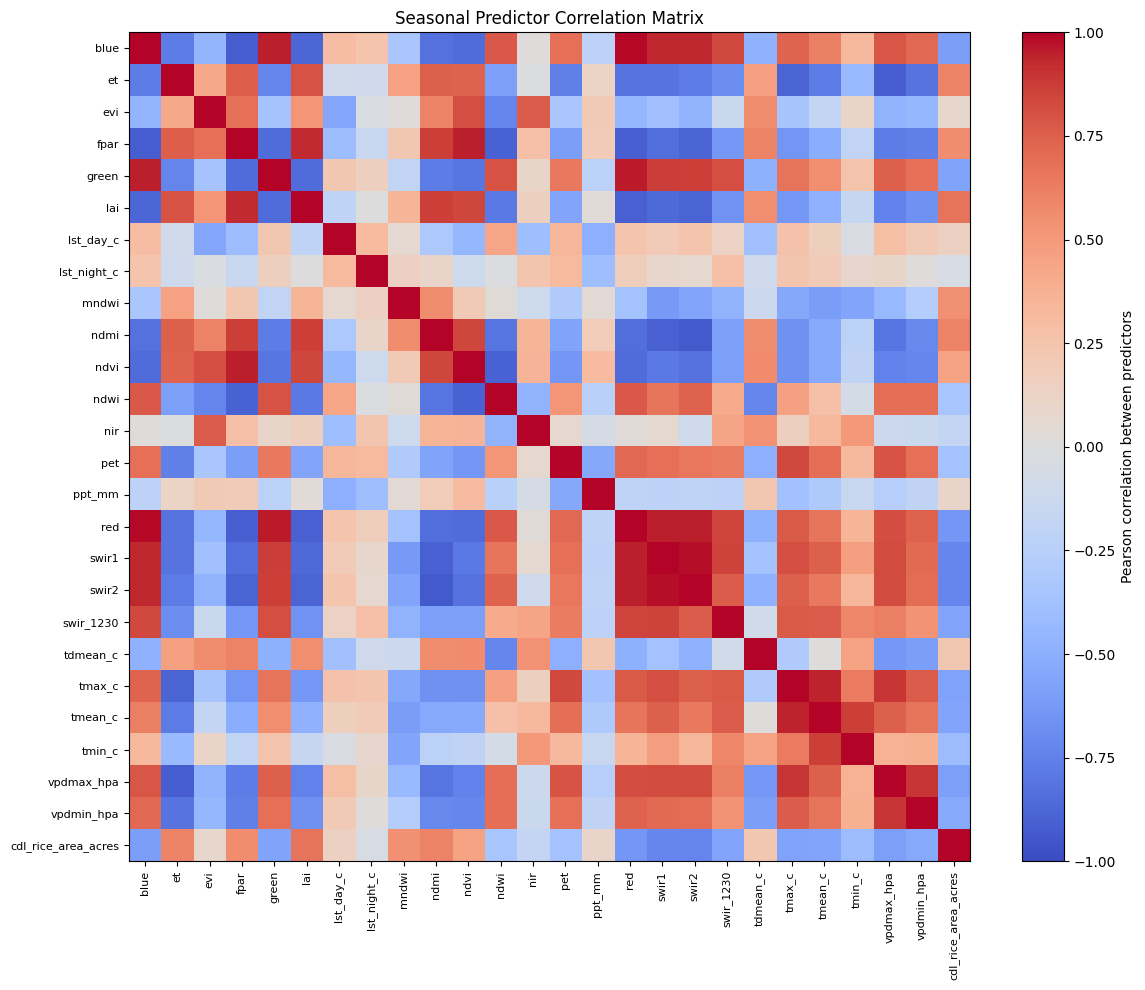

In [21]:
# ============================================================
# Appendix A1 — Seasonal predictor correlation matrix
# ============================================================

app_seasonal_features = list(seasonal_complete)

if "cdl_rice_area_acres" not in app_seasonal_features:
    app_seasonal_features.append("cdl_rice_area_acres")

app_corr = yearly[app_seasonal_features].corr(method="pearson")

app_corr.to_csv(
    APPENDIX_TABLE_DIR / "A1_seasonal_predictor_correlation_matrix.csv"
)

pairs = []
for i, c1 in enumerate(app_corr.columns):
    for j in range(i + 1, len(app_corr.columns)):
        c2 = app_corr.columns[j]
        r = float(app_corr.loc[c1, c2])
        pairs.append({
            "feature_1": c1,
            "feature_2": c2,
            "pearson_r": r,
            "abs_r": abs(r),
        })

app_corr_pairs = (
    pd.DataFrame(pairs)
    .sort_values(["abs_r", "feature_1", "feature_2"], ascending=[False, True, True])
    .reset_index(drop=True)
)

display(app_corr_pairs.head(30))
app_corr_pairs.to_csv(
    APPENDIX_TABLE_DIR / "A1_high_correlation_pairs.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(
    app_corr.values,
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
    aspect="auto"
)
fig.colorbar(im, ax=ax, label="Pearson correlation between predictors")

ax.set_xticks(range(len(app_corr.columns)))
ax.set_xticklabels(app_corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(app_corr.index)))
ax.set_yticklabels(app_corr.index, fontsize=8)

ax.set_title("Seasonal Predictor Correlation Matrix")
appendix_savefig("A1_seasonal_predictor_correlation_matrix")
plt.show()


### Appendix A1 — Interpretation

- Pairs with \(|r|\) close to 1 have very similar annual patterns.
- If many predictor pairs are highly correlated, univariate yield correlations or regression coefficients should not be interpreted as **independent importance**.
- This diagnostic does not identify causes; it visualizes redundancy among predictors.


## Appendix A2. Multicollinearity: Rank Deficiency and Condition Number

The main dataset contains only **19 years**, while there are about 25 seasonal predictors and about 200 monthly predictors.

When `p` (number of predictors) approaches or exceeds `n` (number of years), standard VIF calculations across all variables become unstable.  
Instead, this section first examines the standardized predictor matrix using:

- **matrix rank**
- **non-zero singular values**
- **condition number**
- **number of highly correlated pairs**

If `rank < predictors`, the predictor space contains linear dependencies, making individual coefficients difficult to interpret uniquely.


,dataset,n_rows,n_predictors,matrix_rank,rank_deficient,null_dimension,condition_number_nonzero,pairs_abs_r_ge_0.90
0,seasonal_complete_plus_area,19,26,18,True,8,48.266563,15
1,monthly_timing,19,200,18,True,182,6.022362,195


saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/appendix/A2_singular_value_spectrum.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/appendix/A2_singular_value_spectrum.svg


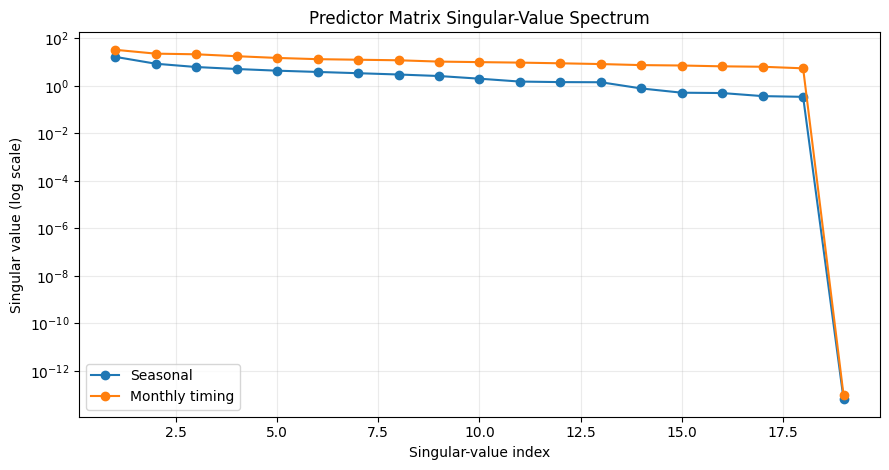

In [22]:
# ============================================================
# Appendix A2 — Multicollinearity diagnostics
# ============================================================

def matrix_diagnostics(df, cols, name, high_corr_threshold=0.90):
    X = df[cols].astype(float).copy()

    nonconstant = [c for c in cols if X[c].nunique() > 1]
    X = X[nonconstant]

    scaler = StandardScaler()
    Xz = scaler.fit_transform(X)

    s = np.linalg.svd(Xz, full_matrices=False, compute_uv=False)

    tol = np.max(s) * max(Xz.shape) * np.finfo(float).eps
    nonzero = s[s > tol]
    rank = int(len(nonzero))

    condition_number_nonzero = (
        float(nonzero.max() / nonzero.min())
        if len(nonzero) >= 2 else np.nan
    )

    corr = X.corr().abs()
    high_pairs = 0
    for i in range(len(corr.columns)):
        for j in range(i + 1, len(corr.columns)):
            if corr.iloc[i, j] >= high_corr_threshold:
                high_pairs += 1

    result = {
        "dataset": name,
        "n_rows": int(X.shape[0]),
        "n_predictors": int(X.shape[1]),
        "matrix_rank": rank,
        "rank_deficient": bool(rank < X.shape[1]),
        "null_dimension": int(max(0, X.shape[1] - rank)),
        "condition_number_nonzero": condition_number_nonzero,
        f"pairs_abs_r_ge_{high_corr_threshold:.2f}": int(high_pairs),
    }

    return result, s

app_diag_rows = []

seasonal_diag, seasonal_s = matrix_diagnostics(
    yearly,
    app_seasonal_features,
    "seasonal_complete_plus_area"
)
app_diag_rows.append(seasonal_diag)

monthly_diag, monthly_s = matrix_diagnostics(
    monthly_model,
    monthly_complete,
    "monthly_timing"
)
app_diag_rows.append(monthly_diag)

app_multicollinearity = pd.DataFrame(app_diag_rows)
display(app_multicollinearity)

app_multicollinearity.to_csv(
    APPENDIX_TABLE_DIR / "A2_multicollinearity_diagnostics.csv",
    index=False
)

plt.figure(figsize=(9, 4.8))
plt.plot(
    np.arange(1, len(seasonal_s) + 1),
    seasonal_s,
    marker="o",
    label="Seasonal"
)
plt.plot(
    np.arange(1, len(monthly_s) + 1),
    monthly_s,
    marker="o",
    label="Monthly timing"
)
plt.yscale("log")
plt.xlabel("Singular-value index")
plt.ylabel("Singular value (log scale)")
plt.title("Predictor Matrix Singular-Value Spectrum")
plt.legend()
plt.grid(alpha=0.25)
appendix_savefig("A2_singular_value_spectrum")
plt.show()


### Appendix A2 — Interpretation

- `rank_deficient = True` indicates that at least some predictors overlap strongly with combinations of other predictors.
- The monthly dataset has roughly 200 predictors for only n=19 years, so an unconstrained multivariable OLS model would be inappropriate to interpret directly.
- Ridge, within-fold `SelectKBest`, and a shallow Random Forest do not eliminate the high-dimensionality and collinearity problem, but they provide more controlled exploratory alternatives than unrestricted OLS.
- This diagnostic is not a causal analysis.


## Appendix A3. Benjamini–Hochberg FDR Correction for Monthly Correlations

The monthly heatmap in the main analysis examines many Pearson correlations across `feature × month` combinations.  
With many simultaneous tests, the chance of observing small p-values by chance increases, so this section applies **BH-FDR correction across all valid monthly tests together**.

The important point is that the correction is applied to the full set of computed feature × month tests, not only to the top features shown in the heatmap.


,feature,month,n,pearson_r,pearson_p,fdr_q_global,fdr_significant_005,abs_r
4,blue,8,19,0.776661,0.000092,0.008880,True,0.776661
148,red,8,19,0.776530,0.000092,0.008880,True,0.776530
82,mndwi,6,19,-0.766806,0.000128,0.008880,True,0.766806
52,green,8,19,0.756580,0.000178,0.009005,True,0.756580
60,lai,8,19,-0.742420,0.000272,0.009005,True,0.742420
84,mndwi,8,19,0.737209,0.000317,0.009005,True,0.737209
184,tmax_c,4,19,0.733962,0.000347,0.009005,True,0.733962
100,ndvi,8,19,-0.728333,0.000406,0.009005,True,0.728333
28,fpar,8,19,-0.727755,0.000413,0.009005,True,0.727755
165,swir2,9,19,0.721978,0.000483,0.009005,True,0.721978


Valid monthly tests: 208
BH-FDR q < 0.05: 35
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/appendix/A3_monthly_yield_heatmap_global_fdr.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/appendix/A3_monthly_yield_heatmap_global_fdr.svg


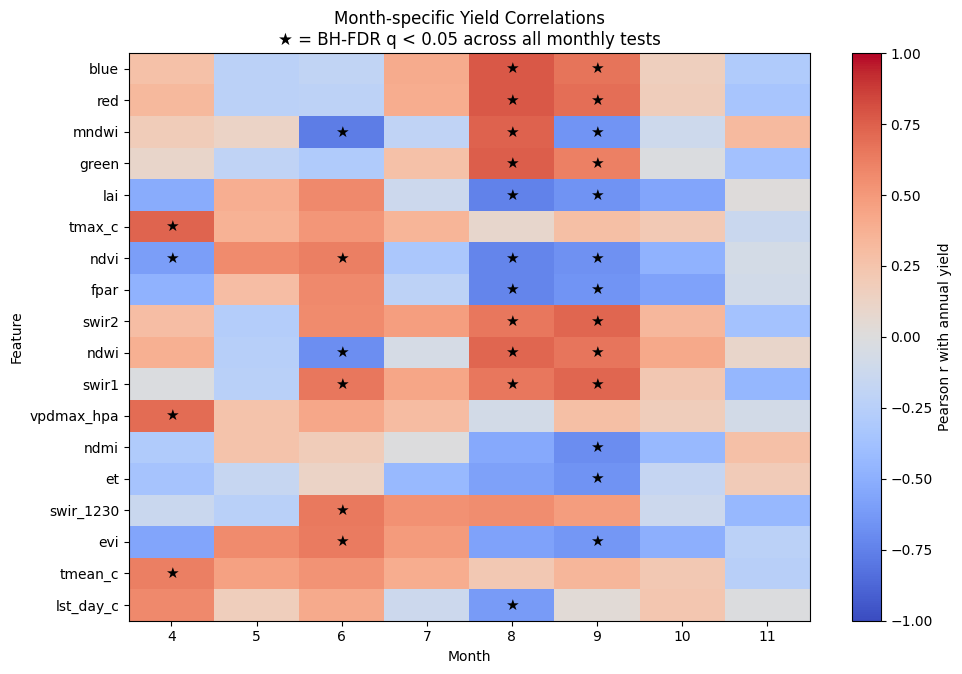

In [23]:
# ============================================================
# Appendix A3 — Global BH-FDR correction across all feature × month tests
# ============================================================

app_monthly_fdr = monthly_yield_corr.copy()

app_monthly_fdr["fdr_q_global"] = appendix_bh(
    app_monthly_fdr["pearson_p"].to_numpy()
)

app_monthly_fdr["fdr_significant_005"] = (
    app_monthly_fdr["fdr_q_global"] < 0.05
)

app_monthly_fdr["abs_r"] = app_monthly_fdr["pearson_r"].abs()

display(
    app_monthly_fdr
    .sort_values(
        ["fdr_significant_005", "abs_r"],
        ascending=[False, False]
    )
    .head(40)
)

print(
    "Valid monthly tests:",
    int(app_monthly_fdr["pearson_p"].notna().sum())
)
print(
    "BH-FDR q < 0.05:",
    int(app_monthly_fdr["fdr_significant_005"].sum())
)

app_monthly_fdr.to_csv(
    APPENDIX_TABLE_DIR / "A3_monthly_yield_correlations_with_global_fdr.csv",
    index=False
)

heat_r = (
    app_monthly_fdr[
        app_monthly_fdr["feature"].isin(top_features)
    ]
    .pivot(
        index="feature",
        columns="month",
        values="pearson_r"
    )
    .reindex(top_features)
)

heat_q = (
    app_monthly_fdr[
        app_monthly_fdr["feature"].isin(top_features)
    ]
    .pivot(
        index="feature",
        columns="month",
        values="fdr_q_global"
    )
    .reindex(top_features)
)

fig, ax = plt.subplots(
    figsize=(10, max(5, 0.38 * len(heat_r)))
)

im = ax.imshow(
    heat_r.values,
    aspect="auto",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

fig.colorbar(
    im,
    ax=ax,
    label="Pearson r with annual yield"
)

ax.set_xticks(range(len(heat_r.columns)))
ax.set_xticklabels([str(m) for m in heat_r.columns])

ax.set_yticks(range(len(heat_r.index)))
ax.set_yticklabels(heat_r.index)

ax.set_xlabel("Month")
ax.set_ylabel("Feature")
ax.set_title(
    "Month-specific Yield Correlations\n"
    "★ = BH-FDR q < 0.05 across all monthly tests"
)

for i in range(heat_q.shape[0]):
    for j in range(heat_q.shape[1]):
        q = heat_q.iloc[i, j]
        if pd.notna(q) and q < 0.05:
            ax.text(
                j,
                i,
                "★",
                ha="center",
                va="center",
                fontsize=11,
                color="black"
            )

appendix_savefig("A3_monthly_yield_heatmap_global_fdr")
plt.show()


### Appendix A3 — Interpretation

- The original heatmap is useful as an exploratory view of Pearson \(r\) effect sizes.
- In the FDR-adjusted version, only cells marked with `★` satisfy **BH-FDR q < 0.05 across all valid monthly tests**.
- A cell that does not survive FDR correction is not evidence that the association is absent; statistical power is limited with n=19.
- Conversely, unadjusted p-values should not be used to make definitive significance claims about individual feature-month combinations.


## Appendix A4. Partial Correlation — Adjusting for Year and CDL Rice Area

Simple correlations between seasonal features and yield may partly reflect:

- long-term temporal trends
- year-to-year variation in rice area

For each seasonal feature, the linear effects of `year` and `cdl_rice_area_acres` are removed from both the feature and yield, and Pearson correlation is then calculated between the residuals.

This is **not a causal method that fully removes confounding**. It is a sensitivity analysis asking whether the association remains after linear adjustment for year and area.


,feature,n,partial_r,partial_p,partial_fdr_q,abs_partial_r
0,lst_night_c,19,0.537536,0.017615,0.266659,0.537536
1,lst_day_c,19,0.510053,0.025676,0.266659,0.510053
2,fpar,19,-0.471864,0.041379,0.266659,0.471864
3,blue,19,0.453583,0.051113,0.266659,0.453583
4,ndvi,19,-0.449793,0.053332,0.266659,0.449793
5,red,19,0.422404,0.071604,0.267694,0.422404
6,swir2,19,0.406212,0.084392,0.267694,0.406212
7,swir1,19,0.388148,0.100556,0.267694,0.388148
8,tmax_c,19,0.379200,0.109344,0.267694,0.379200
9,green,19,0.375705,0.112922,0.267694,0.375705


saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/appendix/A4_partial_correlations_year_area_adjusted.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/appendix/A4_partial_correlations_year_area_adjusted.svg


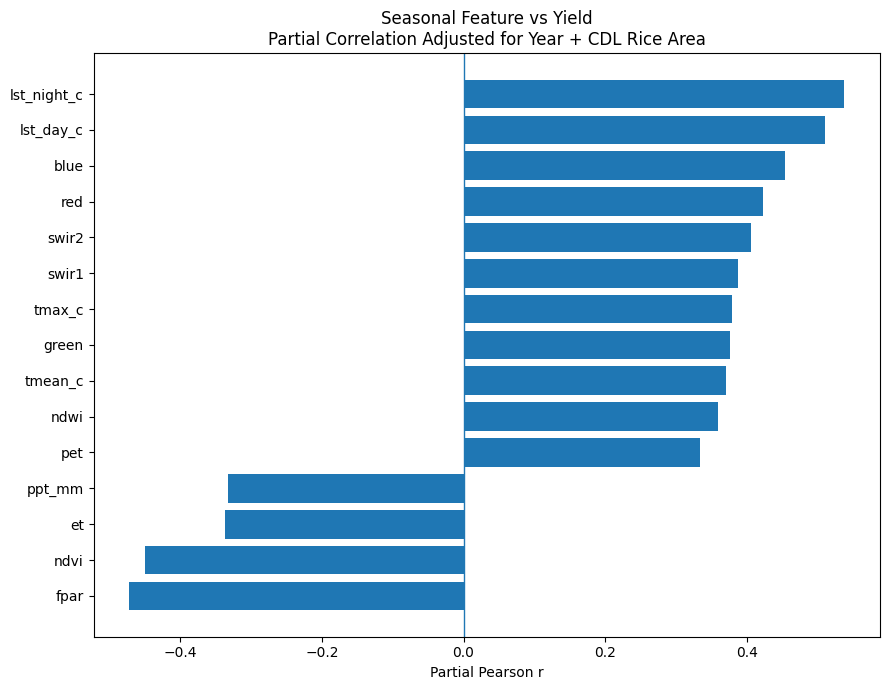

In [24]:
# ============================================================
# Appendix A4 — Partial correlation adjusted for year + CDL area
# ============================================================

def partial_corr_residualized(df, x_col, y_col, controls):
    use_cols = [x_col, y_col] + list(controls)
    d = df[use_cols].dropna().copy()

    if len(d) < 8 or d[x_col].nunique() < 2 or d[y_col].nunique() < 2:
        return {
            "feature": x_col,
            "n": len(d),
            "partial_r": np.nan,
            "partial_p": np.nan,
        }

    C = d[list(controls)].astype(float).to_numpy()
    x = d[x_col].astype(float).to_numpy()
    y = d[y_col].astype(float).to_numpy()

    mx = LinearRegression().fit(C, x)
    my = LinearRegression().fit(C, y)

    rx = x - mx.predict(C)
    ry = y - my.predict(C)

    r, p = pearsonr(rx, ry)

    return {
        "feature": x_col,
        "n": len(d),
        "partial_r": float(r),
        "partial_p": float(p),
    }

app_partial_features = [
    c for c in seasonal_complete
    if c != "cdl_rice_area_acres"
]

app_partial_rows = [
    partial_corr_residualized(
        yearly,
        x_col=c,
        y_col="nass_yield_lb_acre",
        controls=["year", "cdl_rice_area_acres"]
    )
    for c in app_partial_features
]

app_partial = pd.DataFrame(app_partial_rows)

app_partial["partial_fdr_q"] = appendix_bh(
    app_partial["partial_p"].to_numpy()
)

app_partial["abs_partial_r"] = app_partial["partial_r"].abs()

app_partial = (
    app_partial
    .sort_values(
        ["abs_partial_r", "feature"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

display(app_partial.head(25))

app_partial.to_csv(
    APPENDIX_TABLE_DIR / "A4_partial_correlations_year_area_adjusted.csv",
    index=False
)

app_top_partial = (
    app_partial
    .head(15)
    .sort_values("partial_r")
)

plt.figure(figsize=(9, 7))
plt.barh(
    app_top_partial["feature"],
    app_top_partial["partial_r"]
)
plt.axvline(0, linewidth=1)
plt.xlabel("Partial Pearson r")
plt.title(
    "Seasonal Feature vs Yield\n"
    "Partial Correlation Adjusted for Year + CDL Rice Area"
)
appendix_savefig("A4_partial_correlations_year_area_adjusted")
plt.show()


### Appendix A4 — Interpretation

If the simple Pearson correlation and the partial correlation retain a similar direction and magnitude, the association is not fully explained by the linear components of **year and CDL rice area** alone.

However, the analysis does not simultaneously adjust for factors such as:

- other weather variables
- irrigation / water allocation
- cultivar
- management
- spatial selection
- strong collinearity among satellite indicators

Therefore, the partial correlations should **not** be interpreted as causal effects.


## Appendix A5. PCA and Nested-LOOCV PCR

The monthly timing dataset contains about 200 predictors but only 19 annual samples.  
PCA compresses many correlated predictors into **mutually orthogonal principal components**.

This section:

1. Standardizes all monthly predictors across the full 19-year dataset and visualizes **cumulative explained variance** for descriptive purposes
2. For prediction evaluation, performs **standardization + PCA only inside each outer LOOCV training fold**
3. Selects the number of PCA components using 5-fold CV within the outer training data
4. Fits **PCR (Principal Component Regression)** using Linear Regression on the selected principal components

This avoids leakage that would occur if PCA were fit to the full dataset before cross-validation.


,component,explained_variance_ratio,cumulative_explained_variance
0,1,2.902469e-01,0.290247
1,2,1.375565e-01,0.427803
2,3,1.215513e-01,0.549355
3,4,8.396873e-02,0.633323
4,5,6.002013e-02,0.693344
5,6,4.721414e-02,0.740558
6,7,4.232022e-02,0.782878
7,8,3.808586e-02,0.820964
8,9,2.947422e-02,0.850438
9,10,2.660243e-02,0.877040


saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/appendix/A5_pca_monthly_cumulative_variance.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/appendix/A5_pca_monthly_cumulative_variance.svg


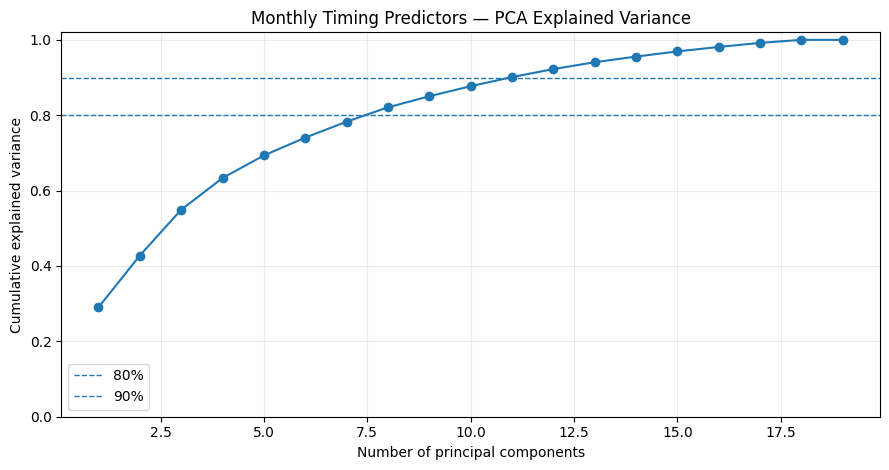

In [25]:
# ============================================================
# Appendix A5-1 — Descriptive PCA explained variance
# ============================================================

X_monthly = monthly_model[monthly_complete].astype(float).copy()

scaler = StandardScaler()
Xz = scaler.fit_transform(X_monthly)

pca_full = PCA()
pca_full.fit(Xz)

cumvar = np.cumsum(pca_full.explained_variance_ratio_)

app_pca_variance = pd.DataFrame({
    "component": np.arange(1, len(cumvar) + 1),
    "explained_variance_ratio": pca_full.explained_variance_ratio_,
    "cumulative_explained_variance": cumvar,
})

display(app_pca_variance.head(20))

app_pca_variance.to_csv(
    APPENDIX_TABLE_DIR / "A5_pca_monthly_explained_variance.csv",
    index=False
)

plt.figure(figsize=(9, 4.8))
plt.plot(
    app_pca_variance["component"],
    app_pca_variance["cumulative_explained_variance"],
    marker="o"
)
plt.axhline(0.80, linestyle="--", linewidth=1, label="80%")
plt.axhline(0.90, linestyle="--", linewidth=1, label="90%")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.ylim(0, 1.02)
plt.title("Monthly Timing Predictors — PCA Explained Variance")
plt.grid(alpha=0.25)
plt.legend()
appendix_savefig("A5_pca_monthly_cumulative_variance")
plt.show()


,model,n,n_predictors_raw,MAE,RMSE,R2,median_selected_components,min_selected_components,max_selected_components
0,Monthly timing PCR nested,19,200,176.982257,216.378736,0.272785,1.0,1,12


,year,actual_yield_lb_acre,pcr_loocv_predicted_yield_lb_acre,selected_n_components
0,2007,8200.0,8596.030136,8
1,2008,8320.0,8683.255320,1
2,2009,8600.0,8593.144052,1
3,2010,8020.0,8195.245382,10
4,2011,8350.0,8187.567259,10
5,2012,8150.0,8437.359511,1
6,2013,8480.0,8665.599060,12
7,2014,8580.0,8569.521619,1
8,2015,8890.0,8756.025567,1
9,2016,8840.0,8452.908629,12


,dataset,model,MAE,RMSE,R2
0,monthly_timing,Random forest,165.730065,211.800411,0.303233
3,monthly_timing,PCR nested,176.982257,216.378736,0.272785
1,monthly_timing,Ridge nested,195.255551,241.751595,0.092237
2,monthly_timing,Mean baseline,210.233918,267.833097,-0.114198


saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/appendix/A5_pcr_observed_vs_nested_loocv.png
saved: /content/drive/MyDrive/プレゼン発表/Foss4G-NA_2026-11-3.4/analysis_outputs/figures/appendix/A5_pcr_observed_vs_nested_loocv.svg


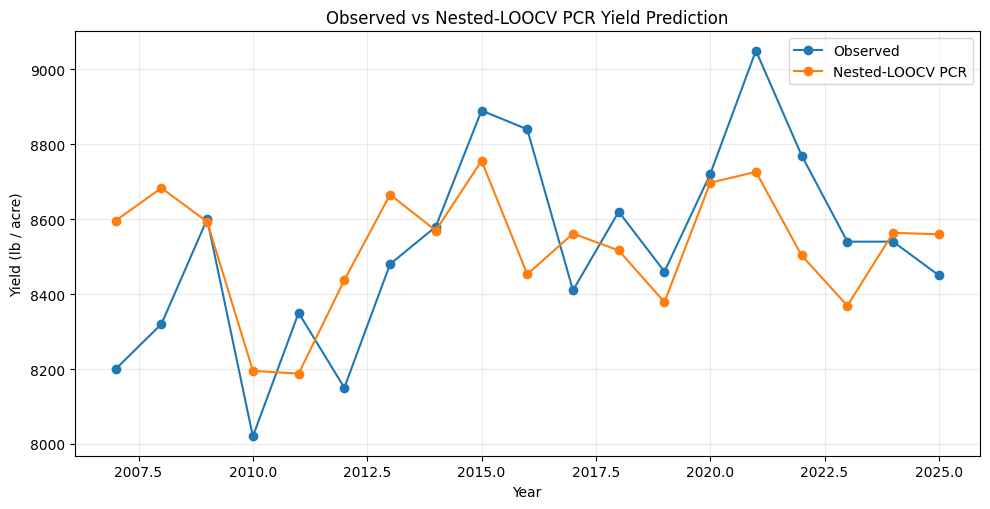

In [26]:
# ============================================================
# Appendix A5-2 — Nested-LOOCV PCR for yield
# ============================================================

def pcr_candidate_components():
    return [1, 2, 3, 5, 8, 10, 12]

def loocv_pcr_nested(X, y, random_state=RANDOM_STATE):
    X = X.astype(float).copy()
    y = pd.Series(y).astype(float).reset_index(drop=True)

    outer = LeaveOneOut()
    pred = np.full(len(y), np.nan, dtype=float)
    chosen_components = []

    for tr, te in outer.split(X):
        Xtr = X.iloc[tr]
        Xte = X.iloc[te]
        ytr = y.iloc[tr]

        inner = KFold(
            n_splits=5,
            shuffle=True,
            random_state=random_state
        )

        max_safe = min(
            X.shape[1],
            max(1, len(Xtr) - int(np.ceil(len(Xtr) / 5)) - 1)
        )

        candidates = [
            k for k in pcr_candidate_components()
            if k <= max_safe
        ]

        if not candidates:
            candidates = [1]

        pipe = Pipeline([
            ("scale", StandardScaler()),
            ("pca", PCA()),
            ("model", LinearRegression()),
        ])

        search = GridSearchCV(
            pipe,
            {"pca__n_components": candidates},
            scoring="neg_mean_squared_error",
            cv=inner,
            n_jobs=-1,
        )

        search.fit(Xtr, ytr)

        pred[te] = search.predict(Xte)
        chosen_components.append(
            int(search.best_params_["pca__n_components"])
        )

    return pred, chosen_components


X_pcr = monthly_model[monthly_complete].astype(float)
y_pcr = monthly_model["nass_yield_lb_acre"].astype(float)

app_pcr_pred, app_pcr_components = loocv_pcr_nested(
    X_pcr,
    y_pcr
)

app_pcr_metrics = {
    "model": "Monthly timing PCR nested",
    "n": len(y_pcr),
    "n_predictors_raw": X_pcr.shape[1],
    "MAE": float(mean_absolute_error(y_pcr, app_pcr_pred)),
    "RMSE": float(np.sqrt(mean_squared_error(y_pcr, app_pcr_pred))),
    "R2": float(r2_score(y_pcr, app_pcr_pred)),
    "median_selected_components": float(np.median(app_pcr_components)),
    "min_selected_components": int(np.min(app_pcr_components)),
    "max_selected_components": int(np.max(app_pcr_components)),
}

app_pcr_metrics_df = pd.DataFrame([app_pcr_metrics])
display(app_pcr_metrics_df)

app_pcr_metrics_df.to_csv(
    APPENDIX_TABLE_DIR / "A5_pcr_nested_loocv_metrics.csv",
    index=False
)

app_pcr_predictions = pd.DataFrame({
    "year": monthly_model["year"].astype(int),
    "actual_yield_lb_acre": y_pcr,
    "pcr_loocv_predicted_yield_lb_acre": app_pcr_pred,
    "selected_n_components": app_pcr_components,
})

display(app_pcr_predictions)

app_pcr_predictions.to_csv(
    APPENDIX_TABLE_DIR / "A5_pcr_nested_loocv_predictions.csv",
    index=False
)

existing_compare = (
    yield_summary[
        (
            (yield_summary["dataset"] == "monthly_timing")
            & (yield_summary["model"].isin(
                ["Mean baseline", "Ridge nested", "Random forest"]
            ))
        )
    ][["dataset", "model", "MAE", "RMSE", "R2"]]
    .copy()
)

pcr_compare_row = pd.DataFrame([{
    "dataset": "monthly_timing",
    "model": "PCR nested",
    "MAE": app_pcr_metrics["MAE"],
    "RMSE": app_pcr_metrics["RMSE"],
    "R2": app_pcr_metrics["R2"],
}])

app_pcr_comparison = pd.concat(
    [existing_compare, pcr_compare_row],
    ignore_index=True
).sort_values("RMSE")

display(app_pcr_comparison)

app_pcr_comparison.to_csv(
    APPENDIX_TABLE_DIR / "A5_pcr_vs_existing_yield_models.csv",
    index=False
)

plt.figure(figsize=(10, 5.2))
plt.plot(
    monthly_model["year"],
    y_pcr,
    marker="o",
    label="Observed"
)
plt.plot(
    monthly_model["year"],
    app_pcr_pred,
    marker="o",
    label="Nested-LOOCV PCR"
)
plt.xlabel("Year")
plt.ylabel("Yield (lb / acre)")
plt.title("Observed vs Nested-LOOCV PCR Yield Prediction")
plt.legend()
plt.grid(alpha=0.25)
appendix_savefig("A5_pcr_observed_vs_nested_loocv")
plt.show()


### Appendix A5 — Interpretation

- PCA does not identify which original variable is causal; it compresses correlated predictors into orthogonal components.
- PCR performance should be compared with Ridge and Random Forest using nested LOOCV RMSE.
- A lack of PCR improvement is not a failure. With n=19, directions of large predictor variance are not necessarily the directions most useful for yield prediction.
- For predictive evaluation, scaling, PCA, component selection, and regression are fitted only within the outer training fold, preventing information leakage from the held-out year.


# Appendix — Interpretation summary

The supplementary analyses reinforce several cautions around the main exploratory results:

- **Predictor dependence:** visible bands, vegetation indices, and temperature variables can be strongly related, so univariate correlations should not be treated as independent causes.
- **High dimensionality:** with only 19 years and many predictors, unrestricted OLS coefficients are not appropriate for direct interpretation.
- **Multiple testing:** month-specific correlations should also be examined with global BH-FDR correction rather than overemphasizing individual feature-month tests.
- **Sensitivity analysis:** partial correlations show how much of a simple seasonal association remains after linearly adjusting for year and rice area.
- **Dimension reduction:** PCR provides an alternative high-dimensional strategy to Ridge and Random Forest and is evaluated with nested LOOCV.

Overall, these diagnostics support treating the reported relationships as **exploratory associations rather than causal effects**.
